# Project 1: Who is likely to drop out, what grade will everyone else get, and how sure are we?

Data: the UCI Student Performance data. The math course has 395 students and the Portuguese course has 649. Each student has 30 background and survey columns plus three grades on a 0 to 20 scale: G1, G2, and the final grade G3. The pass mark is 10.

The notebook follows three questions, in this order:
1. **Who is likely to drop out?** (Part 1)
2. **What grade will everyone else get?** (Part 2)
3. **How sure are we?** (Part 3, with an extension in Part 4 for when there is little data)

The data checks come first. Parts 1 and 2 ask their question at three points in the school year (background only, after G1, after G2) with several kinds of models, Part 3 gives the predictions a range, and Part 4 tests borrowing from the Portuguese course when there are few math students. A couple of extra checks from the first pass are in the appendix.

## Summary

With this dataset, most people would take G1, G2, and the survey columns, fit one model, and report one error number. Domenic and I wanted to do something a little different. The data checks found a small group that behaves differently: 38 math students (9.6%) have a final grade of 0, all of them with 0 absences, and 25 of them still had a G2 above 0. They look like students who dropped out, not students who scored 0, so the project is split into two problems: who is likely to drop out, and what grade will everyone else get. Five kinds of models (ridge, random forest, LightGBM, XGBoost, and CatBoost) are run on both problems at three points in the school year (background only, after G1, after G2), with simple baselines such as copying the last grade, to see where a model actually adds something. I added a third question after reading arXiv papers that used grade data from other schools (not this dataset): how sure are we? Morsomme and Smirnov give each predicted grade a range instead of one number (conformal prediction), and Schwerter et al. use what was learned from one group of students as the starting guess for another, which I tried by using the Portuguese course as the starting guess for the math course.

What is in the notebook: Part 1 predicts dropouts with class weighted models and stratified repeated 5-fold CV (PR-AUC is the main score). Part 2 predicts G3 for the students who stayed (MAE is the main score), then tunes random forest, XGBoost, and LightGBM with 25 random settings each inside a nested CV. Part 3 gives ridge, random forest, LightGBM, and the copy-the-last-grade baseline an 80% range (60/20/20 train, calibration, and test split, repeated over 30 random splits, with a student flagged as "may fail" when the lower end of the range is below 10). Part 4 tests the Portuguese starting guess with 20 to 250 math students, using the 265 Portuguese students who do not look like any math student. The main results: with G1 and G2 the best dropout model reaches a PR-AUC of 0.68 against 0.096 for guessing, but with background only it is 0.29; for math grades, copying G2 (MAE 0.57) beats every model (0.67 for the best one), so the models earn their keep mostly earlier in the year; the ranges shrink from about 8 points wide with background only to 2.4 after G2 for the random forest, and copying G2 gets a range of 2.0; and the Portuguese starting guess helps a lot with 20 math students (MAE 1.347 vs 1.878) and barely at 250 (1.196 vs 1.216). What I would change or look at next: the tuning gains are small compared with the fold to fold noise, the Portuguese dropout results rest on only 15 dropouts, the ranges are the same width for every student (a version that gets wider for students the model is less sure about is worth a try), and the Portuguese course, where the models do beat copying slightly, deserves the same range treatment as math.

Step 1: inspect G1 and G2 for collinearity to target: G3

In [4]:
#inspect both math and portugese classes
import pandas as pd, numpy as np

math_class = pd.read_csv('../data/student-mat.csv', sep=';')
math_class.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [5]:
portugese_class = pd.read_csv('../data/student-por.csv', sep=';')
portugese_class.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


## Collinearity check: correlation, condition number, VIF
Multicollinearity means some predictors are (close to) linear combinations of each other. It doesn't hurt prediction much, but it makes regression coefficients unstable and hard to interpret.

- **Correlation matrix**: pairwise linear relationships. |r| > 0.8 between two *predictors* is a warning sign.
- **Condition number**: how close the predictors are to being linearly dependent as a group.
  - On the correlation matrix it is λ_max / λ_min (largest / smallest eigenvalue). Rough guide: > 30 moderate, > 100 serious.
  - On the standardized data matrix X it is the square root of that (what `np.linalg.cond` gives).
- **VIF (variance inflation factor)**: for each predictor, VIF = 1 / (1 − R²) where R² comes from regressing that predictor on all the others. It equals the diagonal of the inverse correlation matrix. VIF = 1 means no collinearity, > 5 moderate, > 10 serious.

The function below does all of this for one dataset, so it can be run on both the math and Portuguese classes.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def collinearity_report(df, target='G3', features=None, high_corr=0.8, name=''):
    """Correlation heatmaps, collinear pairs, condition numbers, and VIF for one dataset."""
    if features is None:   # default: every numeric column except the target
        features = [c for c in df.select_dtypes(include='number').columns if c != target]
    data = df[features + [target]].apply(pd.to_numeric)

    # 1. full correlation matrix heatmap (lower triangle only, upper is a mirror)
    corr = data.corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    size = max(4, 0.6 * len(corr))
    plt.figure(figsize=(size + 2, size))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
    plt.title(f'{name} correlation matrix')
    plt.show()

    # 2. close-up of G1, G2, G3 (skipped if fewer than 2 of them are in the data)
    grades = list(dict.fromkeys(c for c in ['G1', 'G2', target] if c in corr.columns))
    if len(grades) > 1:
        plt.figure(figsize=(4, 3.5))
        sns.heatmap(corr.loc[grades, grades], annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
        plt.title(f'{name}: G1, G2 vs {target}')
        plt.show()

    # 3. pairs of predictors with |r| >= high_corr
    feat_corr = corr.loc[features, features]
    pairs = [(a, b, feat_corr.loc[a, b])
             for i, a in enumerate(features) for b in features[i + 1:]
             if abs(feat_corr.loc[a, b]) >= high_corr]
    pairs = (pd.DataFrame(pairs, columns=['feature_1', 'feature_2', 'r'])
             .sort_values('r', key=abs, ascending=False).reset_index(drop=True))

    # 4. condition numbers
    eigvals = np.linalg.eigvalsh(feat_corr.values)   # sorted smallest to largest
    cond_corr = eigvals[-1] / eigvals[0]
    X = data[features].values
    X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)
    cond_X = np.linalg.cond(X_scaled)

    # 5. VIF = diagonal of the inverse correlation matrix
    vif = pd.Series(np.diag(np.linalg.inv(feat_corr.values)), index=features,
                    name='VIF').sort_values(ascending=False)

    print(f'===== {name} =====')
    print(f'correlation with {target}:')
    print(corr[target].drop(target).sort_values(key=abs, ascending=False).round(3).head(8).to_string())
    print(f'\npredictor pairs with |r| >= {high_corr}:')
    print(pairs.round(3).to_string() if len(pairs) else '  none')
    print(f'\ncondition number of correlation matrix (lambda_max / lambda_min): {cond_corr:.2f}')
    print(f'condition number of standardized X: {cond_X:.2f}')
    print('\nVIF:')
    print(vif.round(2).to_string())

    return {'corr': corr, 'collinear_pairs': pairs, 'eigenvalues': eigvals,
            'condition_number': cond_corr, 'condition_number_scaled_X': cond_X, 'vif': vif}

### All numeric predictors, both classes

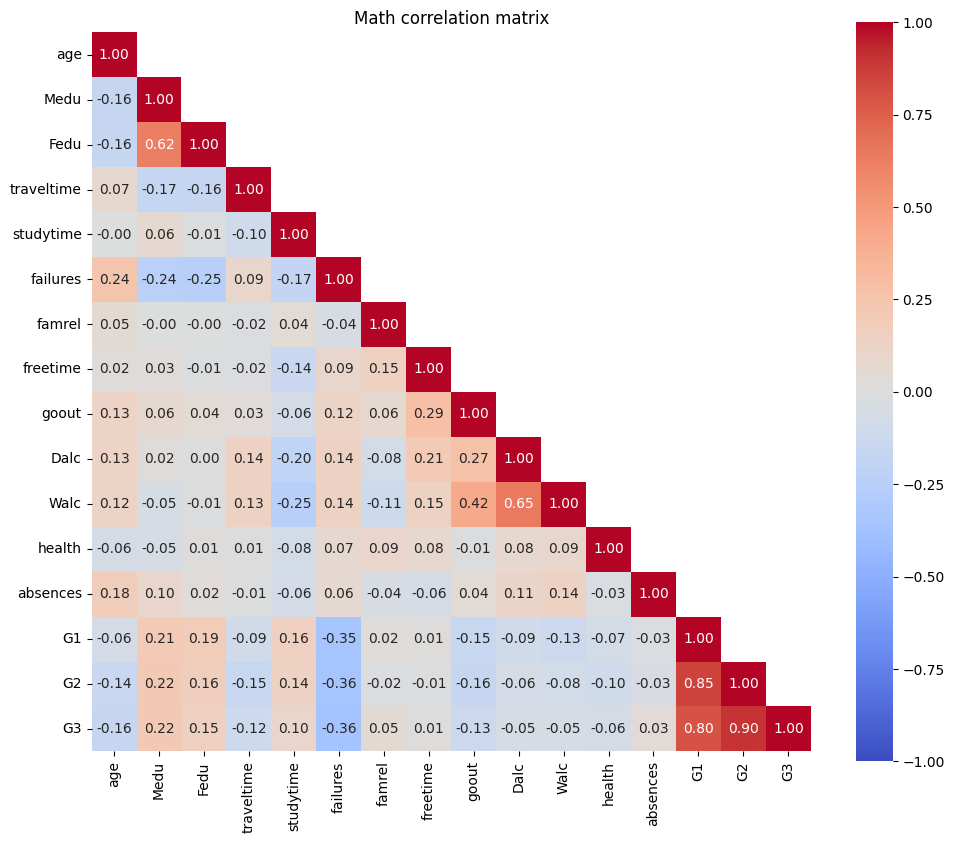

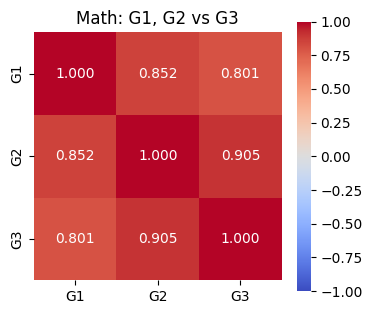

===== Math =====
correlation with G3:
G2            0.905
G1            0.801
failures     -0.360
Medu          0.217
age          -0.162
Fedu          0.152
goout        -0.133
traveltime   -0.117

predictor pairs with |r| >= 0.8:
  feature_1 feature_2      r
0        G1        G2  0.852

condition number of correlation matrix (lambda_max / lambda_min): 20.89
condition number of standardized X: 4.57

VIF:
G2            3.98
G1            3.94
Walc          2.11
Dalc          1.81
Medu          1.77
Fedu          1.72
goout         1.39
failures      1.31
freetime      1.20
age           1.19
studytime     1.15
traveltime    1.09
absences      1.08
famrel        1.08
health        1.06


In [8]:
math_report = collinearity_report(math_class, name='Math')

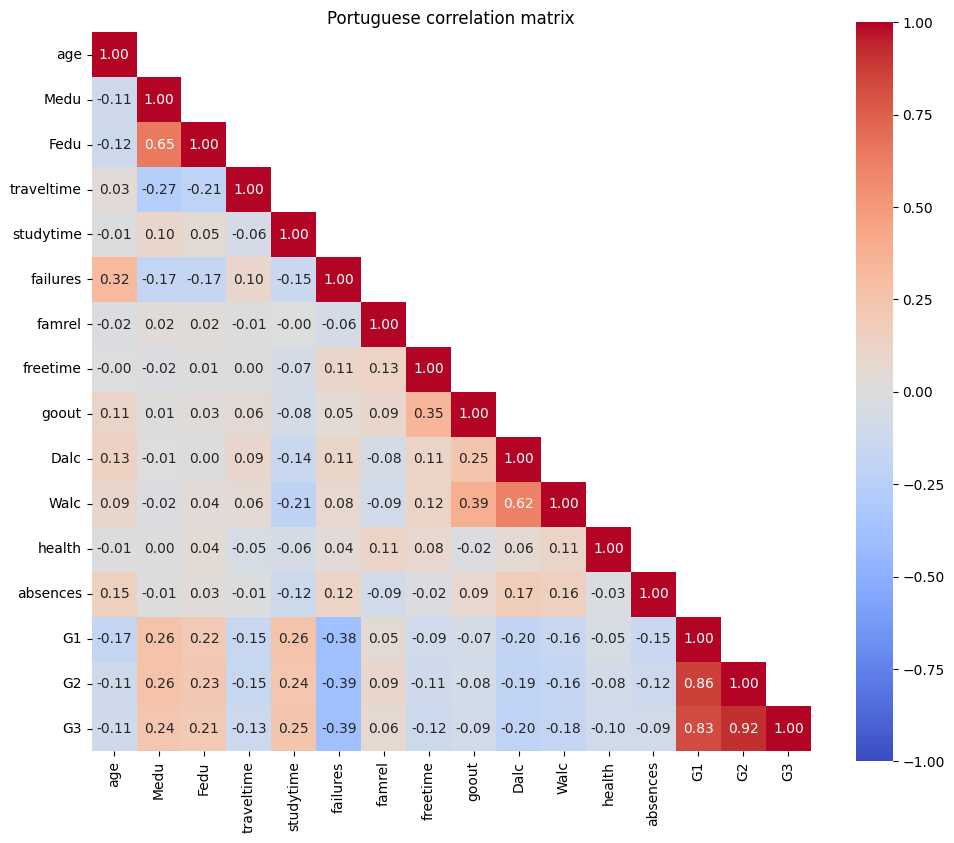

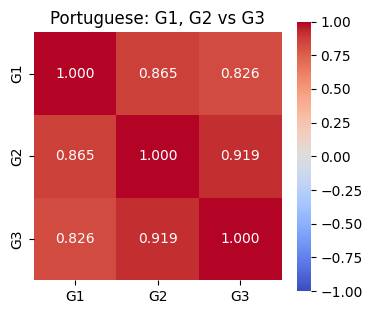

===== Portuguese =====
correlation with G3:
G2           0.919
G1           0.826
failures    -0.393
studytime    0.250
Medu         0.240
Fedu         0.212
Dalc        -0.205
Walc        -0.177

predictor pairs with |r| >= 0.8:
  feature_1 feature_2      r
0        G1        G2  0.865

condition number of correlation matrix (lambda_max / lambda_min): 23.22
condition number of standardized X: 4.82

VIF:
G2            4.21
G1            4.20
Walc          1.90
Medu          1.83
Fedu          1.77
Dalc          1.68
goout         1.37
failures      1.33
age           1.19
freetime      1.19
studytime     1.13
traveltime    1.10
absences      1.09
famrel        1.08
health        1.06


In [9]:
por_report = collinearity_report(portugese_class, name='Portuguese')

### G1 and G2 only
Same function, but only G1 and G2 as predictors, to see how much collinearity there is between just the two earlier grades. With two predictors, VIF = 1 / (1 − r²) where r = corr(G1, G2).

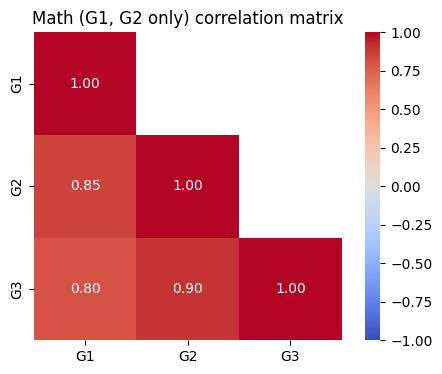

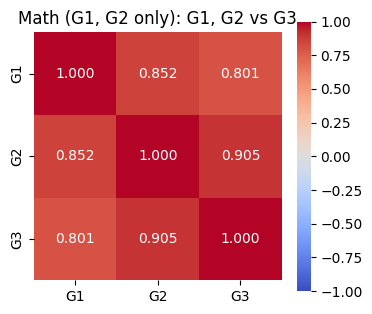

===== Math (G1, G2 only) =====
correlation with G3:
G2    0.905
G1    0.801

predictor pairs with |r| >= 0.8:
  feature_1 feature_2      r
0        G1        G2  0.852

condition number of correlation matrix (lambda_max / lambda_min): 12.52
condition number of standardized X: 3.54

VIF:
G2    3.65
G1    3.65


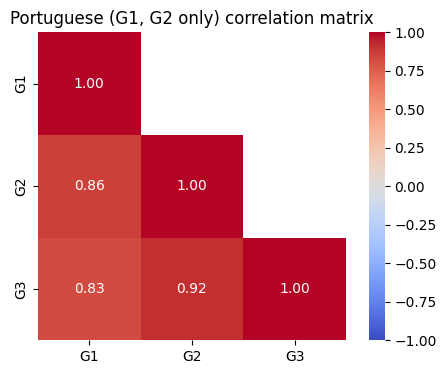

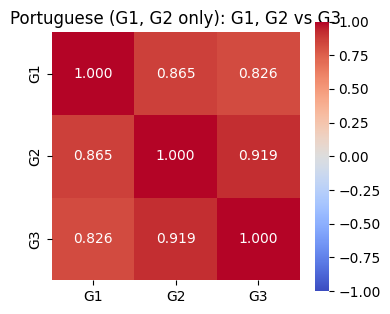

===== Portuguese (G1, G2 only) =====
correlation with G3:
G2    0.919
G1    0.826

predictor pairs with |r| >= 0.8:
  feature_1 feature_2      r
0        G1        G2  0.865

condition number of correlation matrix (lambda_max / lambda_min): 13.81
condition number of standardized X: 3.72

VIF:
G1    3.97
G2    3.97


In [10]:
math_grades_report = collinearity_report(math_class, features=['G1', 'G2'], name='Math (G1, G2 only)')
por_grades_report = collinearity_report(portugese_class, features=['G1', 'G2'], name='Portuguese (G1, G2 only)')

### What the results show
- **G1 and G2 are by far the strongest predictors of G3** in both classes. Math: r(G2, G3) = 0.905, r(G1, G3) = 0.801. Portuguese: r(G2, G3) = 0.919, r(G1, G3) = 0.826. G2 is closer to G3 because it is the more recent grade. The next-best predictor is `failures` at only about −0.36 to −0.39.
- **G1 and G2 are strongly correlated with each other** (0.852 in math, 0.865 in Portuguese). They are the only predictor pair above |r| = 0.8.
- **VIF**: G1 and G2 have VIFs of about 4 in both classes, which is noticeable but below the usual cutoff of 5. Every other predictor is near 1 to 2 (Walc and Dalc are the next highest because they are related to each other). With only G1 and G2 as predictors, VIF = 3.65 (math) and 3.97 (Portuguese), which matches 1 / (1 − r²).
- **Condition number**: about 21 (math) and 23 (Portuguese) for the correlation matrix, and about 4.6 to 4.8 for the standardized X. Both are below the "moderate" threshold of 30, so there is **no severe multicollinearity**.
- **Takeaway**: G1 and G2 carry overlapping information, so in a linear model their individual coefficients will be somewhat unstable (each one "shares credit" with the other). They are not collinear enough to break the model, though. Prediction of G3 should be very good with them included.
- **Math vs Portuguese**: the math class has 38 students with G3 = 0, versus 15 in Portuguese. All 38 math students had a nonzero G1, and 25 of them also had a nonzero G2, so these zeros likely mean the student dropped out or missed the final rather than truly scoring 0. These points pull the math correlations down slightly and are worth looking at before modeling.

## Students who dropped out vs. students who did not drop out
Some students have G3 = 0, and many of those also have G2 = 0. These look like students who **dropped out**, not students who actually scored 0:
- Every student with G2 = 0 also has G3 = 0. They likely left after the first period.
- Other students have G3 = 0 even though G2 > 0. They likely left after the second period.
- **Every student with G3 = 0 has exactly 0 absences**, while the other students average several. Absences were probably just not recorded for students who left. That means `absences` should not be used to predict dropout, or a model would learn a recording artifact.

So the data is split into two problems:
- **Students who dropped out**: classify G3 = 0 (dropped out) vs G3 > 0, using all students.
- **Students who did not drop out**: predict G3 using only students with G3 > 0, so the zeros don't distort the regression.

`split_dropouts` adds a `dropped_out` flag and returns both versions of each dataset.

In [14]:
def split_dropouts(df, name=''):
    """Flag G3 = 0 students as dropouts; return (all students with flag, students who stayed)."""
    df = df.copy()
    df['dropped_out'] = (df['G3'] == 0).astype(int)

    print(f'===== {name} =====')
    print(f"dropouts (G3 = 0): {df['dropped_out'].sum()} of {len(df)} ({df['dropped_out'].mean():.1%})")
    print('\nG2 = 0 vs dropped out:')
    print(pd.crosstab(df['G2'] == 0, df['dropped_out'], rownames=['G2 == 0'], colnames=['dropped_out']))
    print('\nmean absences:')
    print(df.groupby('dropped_out')['absences'].mean().round(2).to_string())
    print()

    stayed = df[df['dropped_out'] == 0].drop(columns='dropped_out')
    return df, stayed

math_all, math_stayed = split_dropouts(math_class, 'Math')
por_all, por_stayed = split_dropouts(portugese_class, 'Portuguese')

===== Math =====
dropouts (G3 = 0): 38 of 395 (9.6%)

G2 = 0 vs dropped out:
dropped_out    0   1
G2 == 0             
False        357  25
True           0  13

mean absences:
dropped_out
0    6.32
1    0.00

===== Portuguese =====
dropouts (G3 = 0): 15 of 649 (2.3%)

G2 = 0 vs dropped out:
dropped_out    0  1
G2 == 0            
False        634  8
True           0  7

mean absences:
dropped_out
0    3.75
1    0.00



In [26]:
for name, stayed, full in [('Math', math_stayed, math_class), ('Portuguese', por_stayed, portugese_class)]:
    assert (stayed['G3'] == 0).sum() == 0, f'{name}: dropouts still present!'
    print(f"{name}: {len(full)} students -> {len(stayed)} who did not drop out, "
          f"{(full['G3'] == 0).sum()} removed, lowest G3 left = {stayed['G3'].min()}")

Math: 395 students -> 357 who did not drop out, 38 removed, lowest G3 left = 4
Portuguese: 649 students -> 634 who did not drop out, 15 removed, lowest G3 left = 1


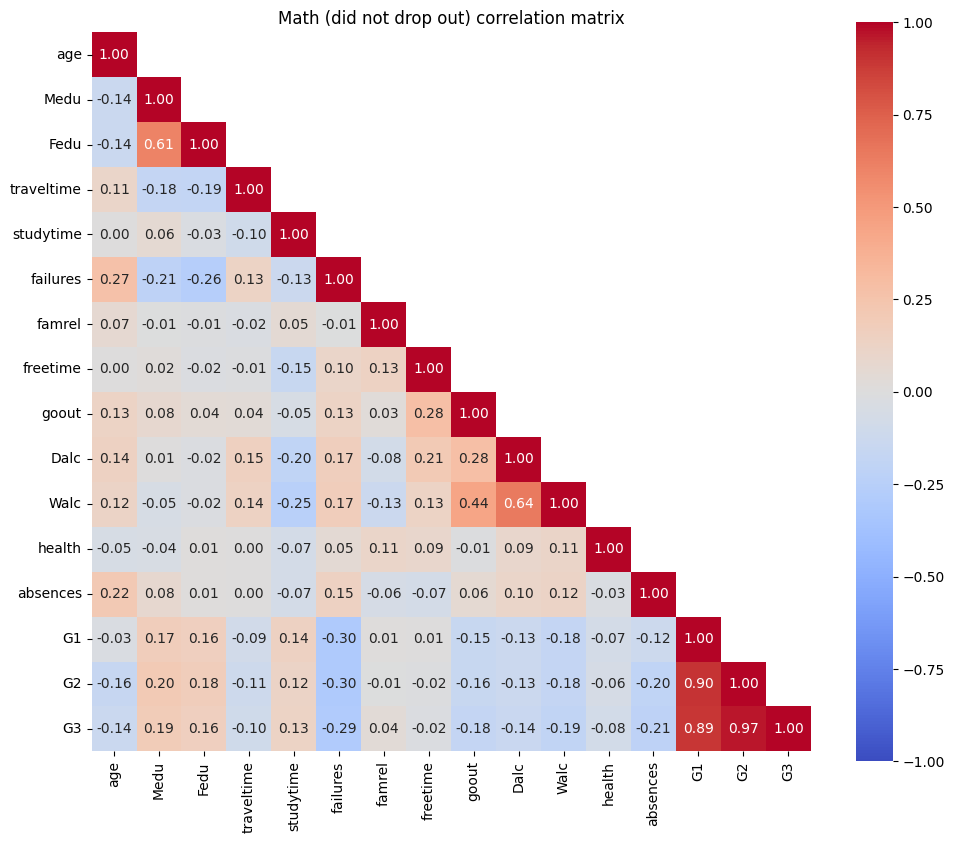

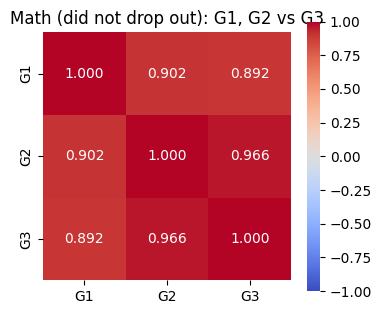

===== Math (did not drop out) =====
correlation with G3:
G2          0.966
G1          0.892
failures   -0.294
absences   -0.213
Medu        0.190
Walc       -0.190
goout      -0.177
Fedu        0.159

predictor pairs with |r| >= 0.8:
  feature_1 feature_2      r
0        G1        G2  0.902

condition number of correlation matrix (lambda_max / lambda_min): 34.50
condition number of standardized X: 5.87

VIF:
G2            6.18
G1            6.09
Walc          2.13
Dalc          1.81
Medu          1.71
Fedu          1.68
goout         1.42
failures      1.29
age           1.27
freetime      1.21
absences      1.15
studytime     1.14
traveltime    1.09
famrel        1.07
health        1.06


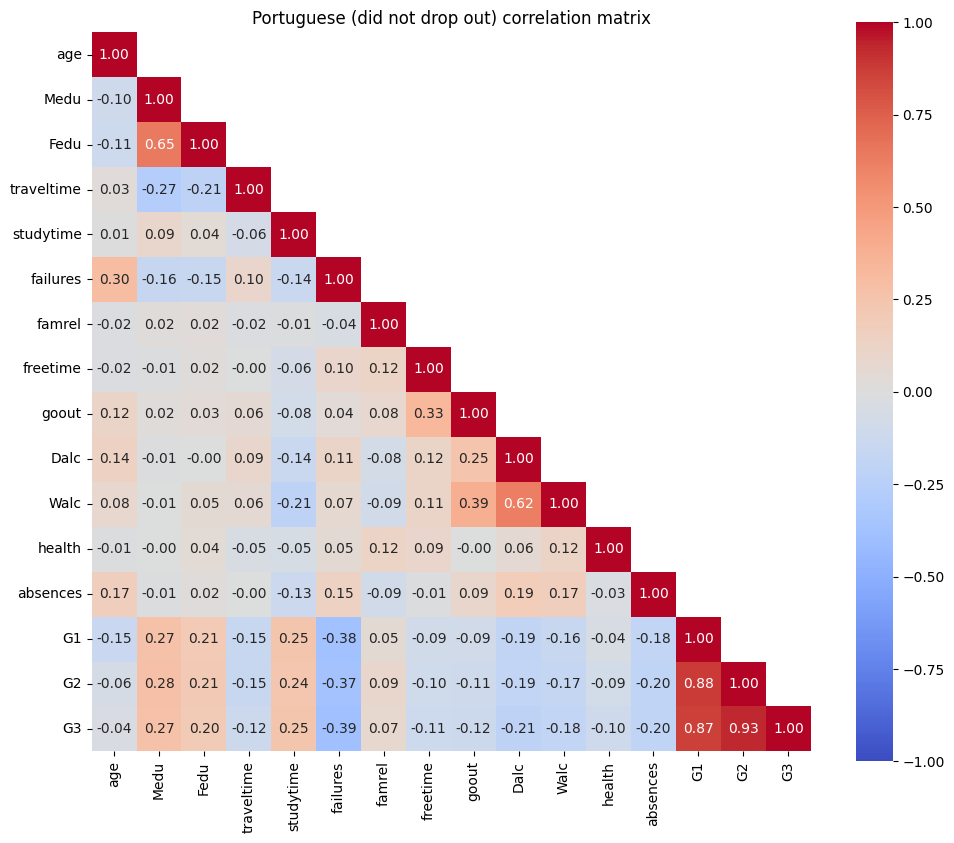

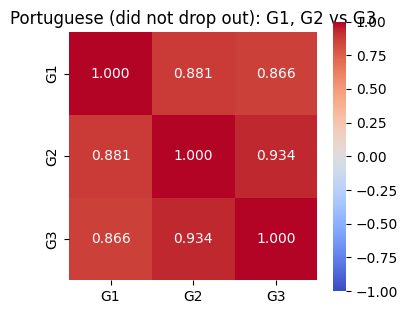

===== Portuguese (did not drop out) =====
correlation with G3:
G2           0.934
G1           0.866
failures    -0.388
Medu         0.272
studytime    0.246
Dalc        -0.211
Fedu         0.197
absences    -0.196

predictor pairs with |r| >= 0.8:
  feature_1 feature_2      r
0        G1        G2  0.881

condition number of correlation matrix (lambda_max / lambda_min): 27.01
condition number of standardized X: 5.20

VIF:
G2            4.88
G1            4.77
Walc          1.91
Medu          1.85
Fedu          1.76
Dalc          1.70
goout         1.36
failures      1.31
age           1.21
freetime      1.18
studytime     1.12
absences      1.12
traveltime    1.10
famrel        1.08
health        1.07


In [19]:
math_stayed_report = collinearity_report(math_stayed, name='Math (did not drop out)')
por_stayed_report = collinearity_report(por_stayed, name='Portuguese (did not drop out)')

### What changes when the dropouts are removed
Dropouts: 38 of 395 in math (9.6%) and 15 of 649 in Portuguese (2.3%). After removing them, 357 math students and 634 Portuguese students remain.

| | Math (all) | Math (did not drop out) | Portuguese (all) | Portuguese (did not drop out) |
|---|---|---|---|---|
| r(G2, G3) | 0.905 | **0.966** | 0.919 | **0.934** |
| r(G1, G3) | 0.801 | **0.892** | 0.826 | **0.866** |
| r(G1, G2) | 0.852 | 0.902 | 0.865 | 0.881 |
| VIF of G1 / G2 | ~3.9 | **~6.1** | ~4.2 | ~4.8 |
| Condition number (corr. matrix) | 20.9 | **34.5** | 23.2 | 27.0 |
| r(absences, G3) | 0.034 | **−0.213** | −0.091 | −0.196 |

- **The grades are even more tied together once the dropouts are gone.** The zeros were the main thing breaking the G1 → G2 → G3 pattern. Among math students who did not drop out, G2 alone explains about 93% of the variance in G3 (0.966² ≈ 0.93).
- **Collinearity is now moderate in math.** The VIFs for G1 and G2 are above 5 and the condition number is above 30. A linear model will have trouble separating the effects of G1 and G2, so its coefficients will be unstable. Tree models like LightGBM aren't affected the same way, because they don't estimate a coefficient for each feature.
- **Absences flipped sign.** In the full math data, absences looked unrelated to G3 (r = 0.034) because the dropouts all had 0 absences and a grade of 0. Among students who did not drop out, more absences means a lower grade (r = −0.213), which is what you'd expect. This confirms that the dropout rows were distorting the data.
- **For students who did not drop out**, any model that includes G2 will be very accurate almost entirely because of G2. The more interesting comparisons are the feature sets without G2 (student background only, or student background + first-period grade), measured against a simple "G3 = G2" baseline.
## Encoding and model evaluation
**Encoding the category columns** (`pd.get_dummies(drop_first=True)`):
- Yes/no columns become a single 0/1 column. For example, `address_U` = 1 for urban and 0 for rural, `Pstatus_T` = 1 if the parents live together, and `higher_yes` = 1 if the student wants higher education.
- Columns with several options (`Mjob`, `Fjob`, `reason`, `guardian`) get one 0/1 column per option, except one. The dropped option is the comparison group. Keeping every option would make the columns always add up to 1, which is perfect collinearity with the intercept.
- Numeric columns that are already ordered (`Medu`, `studytime`, `goout`, ...) stay as they are.

This gives 41 predictor columns (40 for the dropout models, which leave out `absences`). Encoding doesn't learn anything from the data, so it can be done before cross-validation without leakage.

**Evaluating models.** `evaluate_models` runs every model through **repeated cross-validation**: 5 folds, repeated 3 times, so 15 train/test splits. Every model gets exactly the same splits, so the comparison is fair. Standardizing for ridge and logistic regression happens inside a pipeline, so it's refit on each training fold.

**Baselines (no learning).** Each table includes reference "models" that learn nothing. A real model is only useful if it beats them:
- **Average-grade baseline**: predicts every student gets the average G3.
- **Previous-grade baseline (G3 = G1 or G3 = G2)**: predicts the final grade is just the most recent earlier grade.
- **Always "did not drop out" baseline**: predicts that no one drops out. It's right about 90% of the time in math and 98% in Portuguese, which is why accuracy is not used for the dropout models.

**The boosted tree models are kept small** (shallow trees, low learning rate, a minimum number of students per leaf) because the datasets are small and these models overfit easily.

Any model can be added to the comparison:
```python
models = default_models('regression')
models['My model'] = SomeRegressor()
evaluate_models(X, y, models=models, name='...')
```

In [16]:
from sklearn.model_selection import RepeatedKFold, RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.metrics import make_scorer, precision_score, f1_score
from lightgbm import LGBMRegressor, LGBMClassifier
from xgboost import XGBRegressor, XGBClassifier
from catboost import CatBoostRegressor, CatBoostClassifier


def encode(df, target, drop=()):
    """One-hot encode the category columns; return X (every other column) and y."""
    X = pd.get_dummies(df.drop(columns=[target, *drop]), drop_first=True, dtype=int)
    return X, df[target]


class PreviousGradeBaseline(BaseEstimator, RegressorMixin):
    """No-learning reference: predict the final grade as an earlier grade, e.g. G3 = G2."""
    def __init__(self, col='G2'):
        self.col = col

    def fit(self, X, y):
        return self   # nothing to learn

    def predict(self, X):
        return X[self.col].values


def default_models(task, y=None):
    """Fresh, small (regularized) models for task='regression' or 'classification'."""
    if task == 'regression':
        return {
            'Average-grade baseline': DummyRegressor(strategy='mean'),
            'Ridge regression': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
            'Random forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
            'LightGBM': LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=20,
                                      subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                      random_state=42, verbose=-1),
            'XGBoost': XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3,
                                    subsample=0.8, colsample_bytree=0.8, random_state=42),
            'CatBoost': CatBoostRegressor(iterations=500, learning_rate=0.03, depth=4, random_seed=42, verbose=0),
        }
    # classification: every model is told to pay extra attention to the rare dropout class
    pos_weight = (y == 0).sum() / (y == 1).sum() if y is not None else 1.0
    return {
        'Always "did not drop out" baseline': DummyClassifier(strategy='most_frequent'),
        'Logistic regression': make_pipeline(StandardScaler(),
                                             LogisticRegression(class_weight='balanced', max_iter=2000)),
        'Random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced',
                                                random_state=42, n_jobs=-1),
        'LightGBM': LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=10,
                                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                   class_weight='balanced', random_state=42, verbose=-1),
        'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                                 colsample_bytree=0.8, scale_pos_weight=pos_weight, random_state=42),
        'CatBoost': CatBoostClassifier(iterations=500, learning_rate=0.03, depth=4,
                                       auto_class_weights='Balanced', random_seed=42, verbose=0),
    }


def evaluate_models(X, y, task='regression', models=None, name='',
                    n_splits=5, n_repeats=3, seed=42, plot=True):
    """Cross-validate every model on the same folds; return a table of mean and std for each metric."""
    if models is None:
        models = default_models(task, y)

    if task == 'regression':
        cv = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
        scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}
        flip = {'MAE', 'RMSE'}   # sklearn returns these as negatives
        main, ascending = 'MAE', True
    else:
        cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
        scoring = {'ROC-AUC': 'roc_auc', 'PR-AUC': 'average_precision', 'recall': 'recall',
                   'precision': make_scorer(precision_score, zero_division=0),
                   'F1': make_scorer(f1_score, zero_division=0)}
        flip = set()
        main, ascending = 'PR-AUC', False

    rows = []
    for model_name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=scoring)
        row = {'dataset': name, 'model': model_name}
        for metric in scoring:
            vals = scores[f'test_{metric}'] * (-1 if metric in flip else 1)
            row[metric] = vals.mean()
            row[f'{metric}_std'] = vals.std()
        rows.append(row)
    results = pd.DataFrame(rows).sort_values(main, ascending=ascending).reset_index(drop=True)

    if plot:
        plt.figure(figsize=(7, 0.45 * len(results) + 1))
        plt.barh(results['model'], results[main], xerr=results[f'{main}_std'], color='steelblue')
        plt.gca().invert_yaxis()
        plt.xlabel(f"{main} ({'lower' if ascending else 'higher'} is better)")
        plt.title(name)
        plt.tight_layout()
        plt.show()

    print(f'===== {name} =====')
    print(results[['model', *scoring]].round(3).to_string(index=False))
    print()
    return results


# the three feature sets used for both groups of students: name -> grade columns to leave out
feature_sets = {
    'student background only': ('G1', 'G2'),
    'student background + first-period grade (G1)': ('G2',),
    'student background + first- and second-period grades (G1, G2)': (),
}

## Part 1: Who is likely to drop out?

The data checks above found students with a final grade of 0 who look like they left the course. The first question is whether the school could see them coming, so the dropout flag is predicted at each point in the year.

### Three feature sets, from the least to the most information
Every model is run on three feature sets, from the least to the most information:
- **Student background only**: demographics, family, school, and study and social habits, with no grades. This is what a school knows before the year starts.
- **Student background + first-period grade (G1)**: what the school knows after the first period.
- **Student background + first- and second-period grades (G1, G2)**: what the school knows after the second period.

## Students who dropped out: predicting who drops out
The target is `dropped_out` (1 if G3 = 0), using all students. Two columns are always left out:
- `G3`, because it defines the target.
- `absences`, because every student who dropped out has 0 absences, a recording artifact rather than real behavior.

The three feature sets described above are used. Dropouts are rare (9.6% in math, 2.3% in Portuguese), so:
- Every model is weighted to pay extra attention to the dropout class.
- The cross-validation folds are **stratified**, so each fold keeps the same dropout rate.
- The main metric is **PR-AUC** (precision-recall area). It measures how well a model ranks the real dropouts above everyone else. A model that guesses scores about the dropout rate (0.096 in math, 0.023 in Portuguese), and a perfect model scores 1.
- **Recall**: what fraction of the dropouts were caught.
- **Precision**: of the students flagged as dropouts, what fraction actually dropped out.

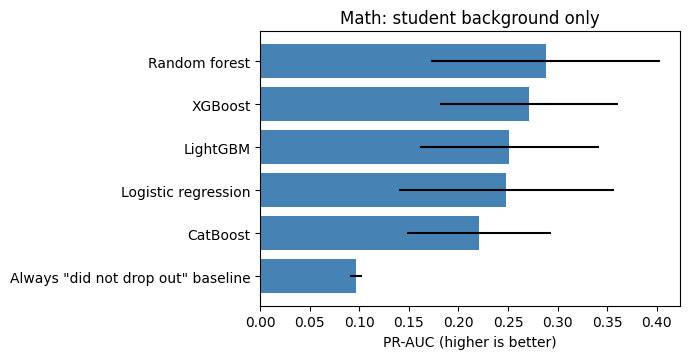

===== Math: student background only =====
                             model  ROC-AUC  PR-AUC  recall  precision    F1
                     Random forest    0.706   0.288   0.089      0.314 0.129
                           XGBoost    0.680   0.271   0.300      0.286 0.287
                          LightGBM    0.687   0.251   0.188      0.237 0.197
               Logistic regression    0.630   0.248   0.435      0.152 0.223
                          CatBoost    0.661   0.221   0.107      0.182 0.129
Always "did not drop out" baseline    0.500   0.096   0.000      0.000 0.000



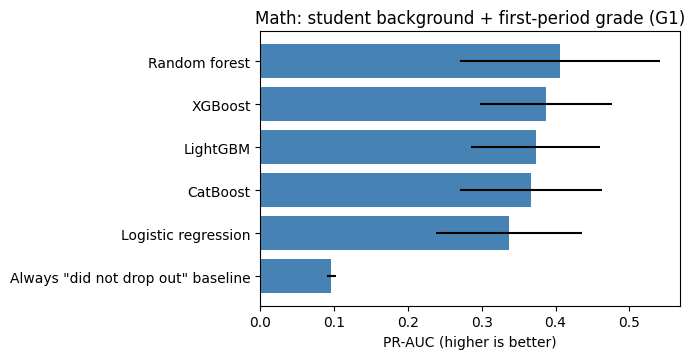

===== Math: student background + first-period grade (G1) =====
                             model  ROC-AUC  PR-AUC  recall  precision    F1
                     Random forest    0.839   0.406   0.292      0.439 0.336
                           XGBoost    0.851   0.387   0.480      0.375 0.415
                          LightGBM    0.848   0.373   0.345      0.335 0.331
                          CatBoost    0.845   0.367   0.294      0.353 0.309
               Logistic regression    0.806   0.337   0.546      0.270 0.356
Always "did not drop out" baseline    0.500   0.096   0.000      0.000 0.000



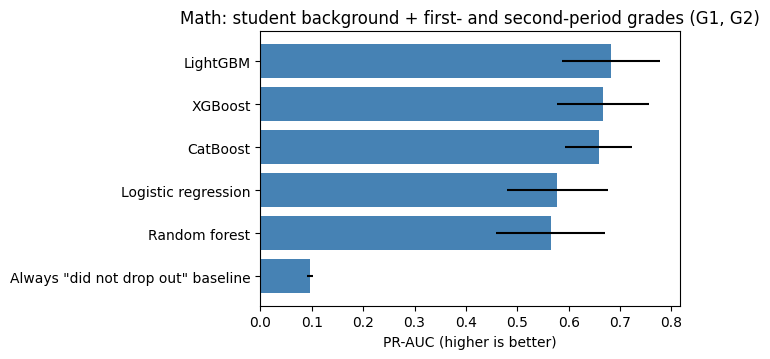

===== Math: student background + first- and second-period grades (G1, G2) =====
                             model  ROC-AUC  PR-AUC  recall  precision    F1
                          LightGBM    0.929   0.682   0.536      0.656 0.572
                           XGBoost    0.924   0.667   0.570      0.566 0.555
                          CatBoost    0.916   0.658   0.544      0.689 0.587
               Logistic regression    0.886   0.578   0.633      0.461 0.517
                     Random forest    0.905   0.565   0.493      0.512 0.483
Always "did not drop out" baseline    0.500   0.096   0.000      0.000 0.000



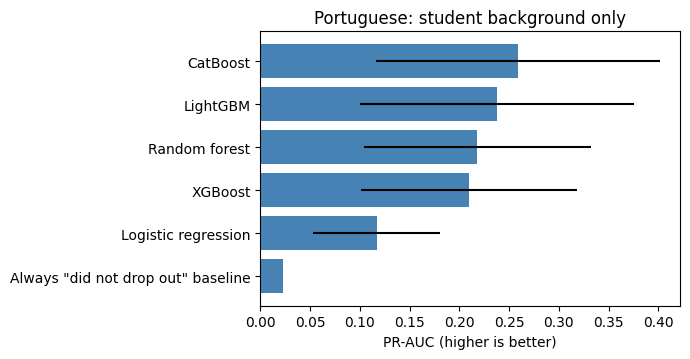

===== Portuguese: student background only =====
                             model  ROC-AUC  PR-AUC  recall  precision    F1
                          CatBoost    0.818   0.259   0.089      0.156 0.109
                          LightGBM    0.835   0.238   0.089      0.178 0.111
                     Random forest    0.861   0.218   0.000      0.000 0.000
                           XGBoost    0.810   0.210   0.111      0.102 0.104
               Logistic regression    0.775   0.117   0.289      0.075 0.117
Always "did not drop out" baseline    0.500   0.023   0.000      0.000 0.000



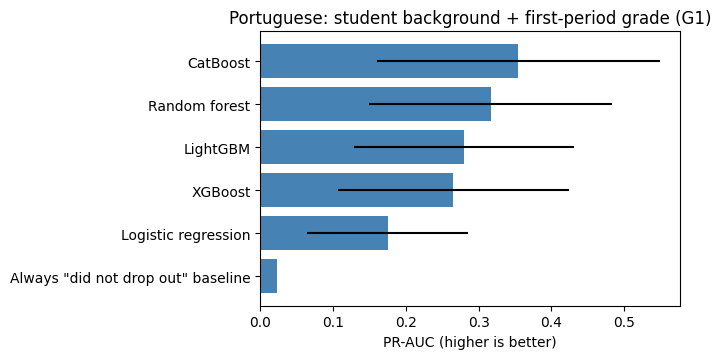

===== Portuguese: student background + first-period grade (G1) =====
                             model  ROC-AUC  PR-AUC  recall  precision    F1
                          CatBoost    0.889   0.355   0.244      0.272 0.234
                     Random forest    0.910   0.316   0.089      0.222 0.122
                          LightGBM    0.842   0.280   0.178      0.184 0.161
                           XGBoost    0.839   0.265   0.289      0.233 0.229
               Logistic regression    0.806   0.175   0.422      0.129 0.192
Always "did not drop out" baseline    0.500   0.023   0.000      0.000 0.000



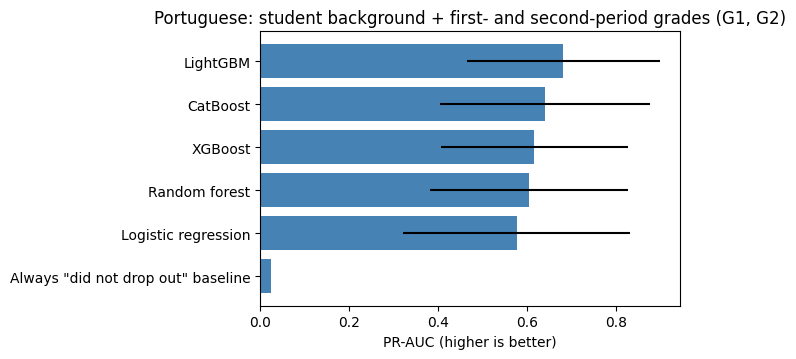

===== Portuguese: student background + first- and second-period grades (G1, G2) =====
                             model  ROC-AUC  PR-AUC  recall  precision    F1
                          LightGBM    0.904   0.682   0.600      0.723 0.617
                          CatBoost    0.960   0.641   0.533      0.480 0.482
                           XGBoost    0.928   0.616   0.556      0.516 0.507
                     Random forest    0.961   0.604   0.333      0.511 0.383
               Logistic regression    0.901   0.576   0.600      0.370 0.429
Always "did not drop out" baseline    0.500   0.023   0.000      0.000 0.000



dataset,"Math: student background + first- and second-period grades (G1, G2)",Math: student background + first-period grade (G1),Math: student background only,"Portuguese: student background + first- and second-period grades (G1, G2)",Portuguese: student background + first-period grade (G1),Portuguese: student background only
model,,,,,,
"Always ""did not drop out"" baseline",0.096,0.096,0.096,0.023,0.023,0.023
CatBoost,0.658,0.367,0.221,0.641,0.355,0.259
LightGBM,0.682,0.373,0.251,0.682,0.280,0.238
Logistic regression,0.578,0.337,0.248,0.576,0.175,0.117
Random forest,0.565,0.406,0.288,0.604,0.316,0.218
XGBoost,0.667,0.387,0.271,0.616,0.265,0.210


In [18]:
dropped_out_results = []
for subject, df in [('Math', math_all), ('Portuguese', por_all)]:
    for label, drop in feature_sets.items():
        X, y = encode(df, 'dropped_out', drop=('G3', 'absences', *drop))
        dropped_out_results.append(evaluate_models(X, y, task='classification', name=f'{subject}: {label}'))

# PR-AUC of every model on every dataset / feature set in one table
dropped_out_table = pd.concat(dropped_out_results)
dropped_out_table.pivot(index='model', columns='dataset', values='PR-AUC').round(3)

### What the results show: students who dropped out
Best PR-AUC per feature set (guessing scores 0.096 in math and 0.023 in Portuguese):

| | Math | Portuguese |
|---|---|---|
| **Student background only** | 0.29 (random forest) | 0.26 (CatBoost) |
| **Student background + G1** | 0.41 (random forest) | 0.36 (CatBoost) |
| **Student background + G1, G2** | **0.68 (LightGBM)** | **0.68 (LightGBM)** |

- **Student background only**: the models do better than guessing (about 3 times the base rate in math), but they can't reliably find dropouts. At best they catch about 30 to 40% of dropouts with low precision. Logistic regression catches the most (about 44% in math), but most of the students it flags didn't actually drop out (precision 0.15).
- **Adding G1 helps a lot.** A low first-period grade is an early warning sign. Every student who dropped out had a G1 between 4 and 12.
- **With G1 and G2, LightGBM is the best model in both subjects.** In math it catches about 54% of dropouts, and about 66% of the students it flags really did drop out. Part of this is easy: 13 of the 38 math dropouts (and 7 of 15 in Portuguese) already have G2 = 0, which gives them away. The harder cases are the students who still had a G2 grade and then left.
- **Portuguese results are unreliable.** There are only 15 dropouts, so each test fold has just 3. One student more or less caught changes recall by about 33 percentage points, which is why the scores jump around between models (for example, random forest has a high ROC-AUC but catches almost no one with student background only).
- **Takeaway**: dropout is hard to predict before any grades exist. The first-period grade is the most useful early signal, and by the second period the boosted models (LightGBM, CatBoost, XGBoost) do a reasonable job.

In [33]:
print((math_all["G2"]==0).sum())
print((por_all["G2"]==0).sum())

13
7


## Part 2: What grade will everyone else get?

With the dropouts set aside, the second question is the final grade of the students who stayed. This is also where I check whether a model beats just copying the last grade.

## Students who did not drop out: predicting the final grade (G3)
Every model is run on the three feature sets described above.

When G1 or G2 is available, a previous-grade baseline is added (G3 = G1, or G3 = G2) to check whether the models add anything beyond copying the latest grade. The main metric is **MAE**: the average error in grade points on the 0 to 20 scale.

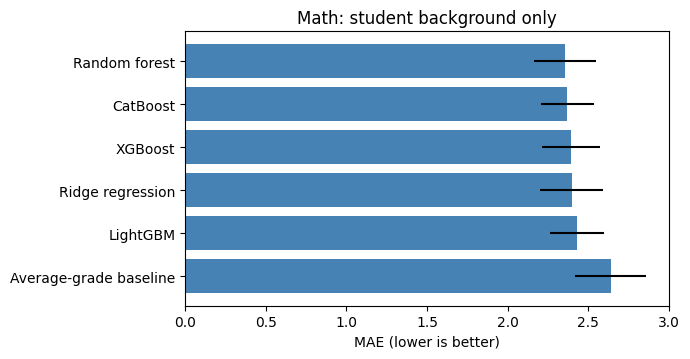

===== Math: student background only =====
                 model   MAE  RMSE     R2
         Random forest 2.356 2.907  0.174
              CatBoost 2.370 2.920  0.164
               XGBoost 2.391 2.931  0.156
      Ridge regression 2.396 2.959  0.141
              LightGBM 2.431 2.993  0.121
Average-grade baseline 2.637 3.221 -0.012



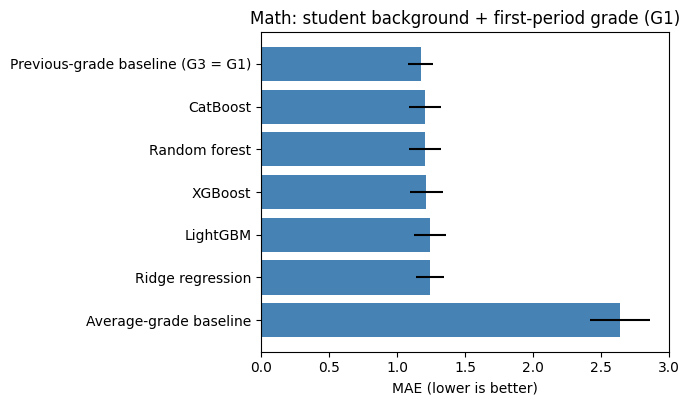

===== Math: student background + first-period grade (G1) =====
                            model   MAE  RMSE     R2
Previous-grade baseline (G3 = G1) 1.174 1.520  0.771
                         CatBoost 1.206 1.469  0.787
                    Random forest 1.206 1.484  0.782
                          XGBoost 1.215 1.495  0.779
                         LightGBM 1.243 1.527  0.769
                 Ridge regression 1.244 1.508  0.775
           Average-grade baseline 2.637 3.221 -0.012



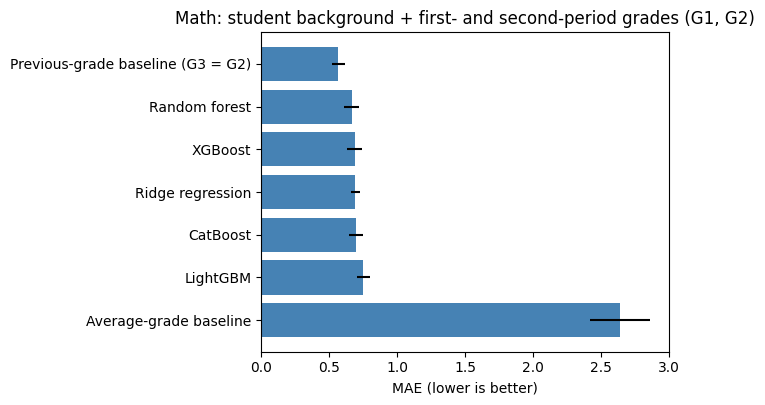

===== Math: student background + first- and second-period grades (G1, G2) =====
                            model   MAE  RMSE     R2
Previous-grade baseline (G3 = G2) 0.569 0.853  0.927
                    Random forest 0.667 0.867  0.925
                          XGBoost 0.689 0.884  0.922
                 Ridge regression 0.695 0.881  0.923
                         CatBoost 0.699 0.897  0.921
                         LightGBM 0.753 0.950  0.911
           Average-grade baseline 2.637 3.221 -0.012



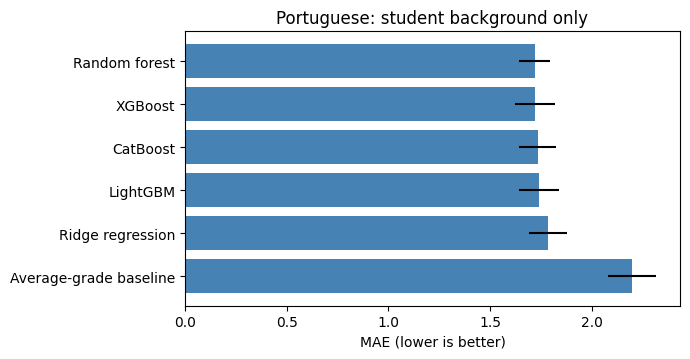

===== Portuguese: student background only =====
                 model   MAE  RMSE     R2
         Random forest 1.719 2.180  0.336
               XGBoost 1.721 2.185  0.333
              CatBoost 1.733 2.195  0.327
              LightGBM 1.740 2.210  0.317
      Ridge regression 1.787 2.257  0.288
Average-grade baseline 2.199 2.690 -0.007



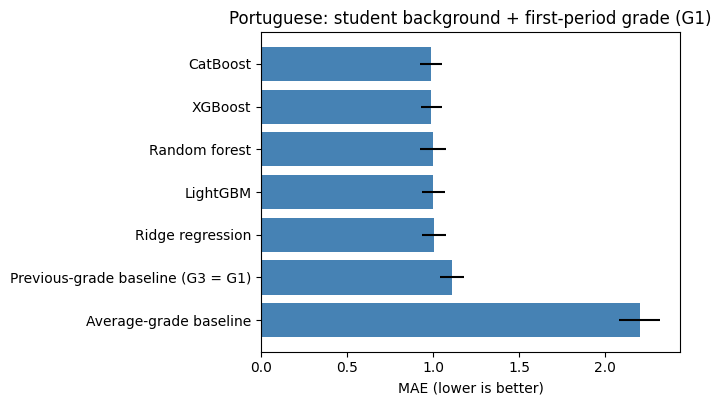

===== Portuguese: student background + first-period grade (G1) =====
                            model   MAE  RMSE     R2
                         CatBoost 0.985 1.275  0.773
                          XGBoost 0.989 1.276  0.772
                    Random forest 0.998 1.294  0.766
                         LightGBM 1.000 1.286  0.769
                 Ridge regression 1.003 1.323  0.755
Previous-grade baseline (G3 = G1) 1.109 1.545  0.665
           Average-grade baseline 2.199 2.690 -0.007



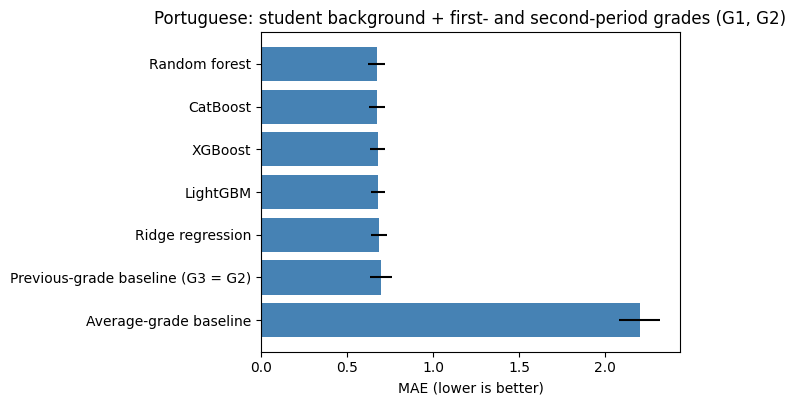

===== Portuguese: student background + first- and second-period grades (G1, G2) =====
                            model   MAE  RMSE     R2
                    Random forest 0.671 0.931  0.876
                         CatBoost 0.673 0.935  0.876
                          XGBoost 0.678 0.943  0.874
                         LightGBM 0.679 0.937  0.875
                 Ridge regression 0.684 0.938  0.876
Previous-grade baseline (G3 = G2) 0.696 1.051  0.844
           Average-grade baseline 2.199 2.690 -0.007



dataset,"Math: student background + first- and second-period grades (G1, G2)",Math: student background + first-period grade (G1),Math: student background only,"Portuguese: student background + first- and second-period grades (G1, G2)",Portuguese: student background + first-period grade (G1),Portuguese: student background only
model,,,,,,
Average-grade baseline,2.637,2.637,2.637,2.199,2.199,2.199
CatBoost,0.699,1.206,2.370,0.673,0.985,1.733
LightGBM,0.753,1.243,2.431,0.679,1.000,1.740
Previous-grade baseline (G3 = G1),NaN,1.174,NaN,NaN,1.109,NaN
Previous-grade baseline (G3 = G2),0.569,NaN,NaN,0.696,NaN,NaN
Random forest,0.667,1.206,2.356,0.671,0.998,1.719
Ridge regression,0.695,1.244,2.396,0.684,1.003,1.787
XGBoost,0.689,1.215,2.391,0.678,0.989,1.721


In [17]:
did_not_drop_out_results = []
for subject, df in [('Math', math_stayed), ('Portuguese', por_stayed)]:
    for label, drop in feature_sets.items():
        X, y = encode(df, 'G3', drop=drop)
        models = default_models('regression')
        if 'G2' in X:
            models['Previous-grade baseline (G3 = G2)'] = PreviousGradeBaseline('G2')
        elif 'G1' in X:
            models['Previous-grade baseline (G3 = G1)'] = PreviousGradeBaseline('G1')
        did_not_drop_out_results.append(evaluate_models(X, y, models=models, name=f'{subject}: {label}'))

# MAE of every model on every dataset / feature set in one table
did_not_drop_out_table = pd.concat(did_not_drop_out_results)
did_not_drop_out_table.pivot(index='model', columns='dataset', values='MAE').round(3)

### What the results show: students who did not drop out
MAE (average error in grade points; lower is better):

| | Math | Portuguese |
|---|---|---|
| Average-grade baseline | 2.64 | 2.20 |
| **Student background only**, best model | 2.36 (random forest), R² = 0.17 | 1.72 (random forest), R² = 0.34 |
| **Student background + G1**, best model | 1.21 (CatBoost / random forest) | 0.99 (CatBoost) |
| Previous-grade baseline (G3 = G1) | **1.17** | 1.11 |
| **Student background + G1, G2**, best model | 0.67 (random forest) | 0.67 (random forest) |
| Previous-grade baseline (G3 = G2) | **0.57** | 0.70 |

- **Student background only**: the models beat the average-grade baseline, but not by much. They explain only about 17% (math) to 34% (Portuguese) of the variance in G3. Background matters, but it leaves most of a student's final grade unexplained.
- **Once a previous grade is known, it does almost all the work.** In **math**, simply copying the previous grade is *better* than every model, by MAE, both with G1 alone (1.17) and with G1 and G2 (0.57). The models add noise on top of a nearly perfect rule, partly because about half of the math students have G3 exactly equal to G2. (By RMSE, which punishes big misses more, the models are slightly better, so they mainly help on the few students whose grade changed a lot.) In **Portuguese**, the models beat the previous-grade baseline slightly (0.99 vs 1.11 with G1, and 0.67 vs 0.70 with G2), so student background adds a little information there.
- **Model comparison**: the tree models (random forest, CatBoost, XGBoost, LightGBM) are all within about 0.05 to 0.1 grade points of each other, and ridge regression is close behind. With this little data, the choice of model matters much less than which features are available. LightGBM was the weakest tree model in math in all three feature sets, possibly because it overfits more easily on a dataset this small.
- **Takeaway**: for students who did not drop out, the final grade is mostly decided by how they were already doing. The most useful prediction is the early one (student background only, or + G1), when a school could still step in.

## Tuning random forest, XGBoost and LightGBM (students who did not drop out)
The earlier models used hand-picked settings (hyperparameters), such as tree depth, number of trees, and learning rate. **Tuning** tries many combinations of settings and keeps the one with the lowest error.

**Randomized search.** For each model, `RandomizedSearchCV` tries 25 random combinations from a range of settings. It scores each combination with 3-fold cross-validation and keeps the one with the lowest MAE.

**Why the tuning runs inside the cross-validation (nested cross-validation).** If you try 25 combinations and report the best score, part of that score is luck: one combination happened to suit those particular test students. To avoid this, each search is passed to `evaluate_models` like any other model:
- **Outer loop (5 folds):** splits the students into training and test sets. It is used only to measure the final error.
- **Inner loop:** inside each outer training set, the randomized search picks the best settings using only those training students.
- The tuned model is then scored on the outer test students, which it has never seen, not even during tuning.

So the MAE reported below is an honest estimate for new students.
- **5 outer folds instead of 5 × 3:** each tuned model runs a full search in every fold, so 15 folds would take about 3 times as long. The dummy (average-grade) and previous-grade baselines are scored on the same 5 folds.
- **Final models:** after the comparison, each search is run once more on every student in that dataset. That gives the best settings shown below, and the fitted models used for the feature-importance graphs and the tree drawing.

In [34]:
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import RandomizedSearchCV, KFold


def tuned_models(n_iter=25, seed=42):
    """Random forest, XGBoost and LightGBM, each wrapped in a randomized search over its settings."""
    inner_cv = KFold(n_splits=3, shuffle=True, random_state=seed)

    def search(model, settings):
        return RandomizedSearchCV(model, settings, n_iter=n_iter, cv=inner_cv,
                                  scoring='neg_mean_absolute_error', n_jobs=-1, random_state=seed)

    return {
        'Random forest (tuned)': search(RandomForestRegressor(random_state=seed, n_jobs=1), {
            'n_estimators': randint(200, 601),
            'max_depth': [None, 4, 6, 8, 12],
            'min_samples_leaf': [1, 2, 5, 10, 20],
            'max_features': ['sqrt', 0.3, 0.5, 1.0],
        }),
        'XGBoost (tuned)': search(XGBRegressor(importance_type='total_gain', random_state=seed, n_jobs=1), {
            'n_estimators': randint(100, 801),
            'learning_rate': loguniform(0.01, 0.2),
            'max_depth': randint(2, 7),
            'min_child_weight': [1, 3, 5, 10],
            'subsample': uniform(0.6, 0.4),          # 0.6 to 1.0
            'colsample_bytree': uniform(0.6, 0.4),
            'reg_lambda': loguniform(1e-3, 10),
        }),
        'LightGBM (tuned)': search(LGBMRegressor(subsample_freq=1, importance_type='gain',
                                                 random_state=seed, n_jobs=1, verbose=-1), {
            'n_estimators': randint(100, 801),
            'learning_rate': loguniform(0.01, 0.2),
            'num_leaves': [4, 8, 16, 31],
            'min_child_samples': [5, 10, 20, 40],
            'subsample': uniform(0.6, 0.4),
            'colsample_bytree': uniform(0.6, 0.4),
            'reg_lambda': loguniform(1e-3, 10),
        }),
    }

In [35]:
tuned_results = []
tuned_fits = {}   # (subject, feature set, model) -> search refit on every student in that dataset
for subject, df in [('Math', math_stayed), ('Portuguese', por_stayed)]:
    for label, drop in feature_sets.items():
        X, y = encode(df, 'G3', drop=drop)
        models = {'Average-grade baseline': DummyRegressor(strategy='mean')}
        if 'G2' in X:
            models['Previous-grade baseline (G3 = G2)'] = PreviousGradeBaseline('G2')
        elif 'G1' in X:
            models['Previous-grade baseline (G3 = G1)'] = PreviousGradeBaseline('G1')
        models.update(tuned_models())
        # 5 outer folds (n_repeats=1): each tuned model runs a full search inside every outer fold
        tuned_results.append(evaluate_models(X, y, models=models, name=f'{subject}: {label}',
                                             n_repeats=1, plot=False))

        # final models: tune once more on every student, for the best settings and the importance graphs
        for model_name, search in tuned_models().items():
            tuned_fits[(subject, label, model_name)] = search.fit(X, y)

tuned_table = pd.concat(tuned_results)

# best settings found for each model on each dataset
for model_name in ['Random forest (tuned)', 'XGBoost (tuned)', 'LightGBM (tuned)']:
    settings = pd.DataFrame({f'{s}: {l}': fit.best_params_ for (s, l, m), fit in tuned_fits.items() if m == model_name}).T
    print(f'===== best settings: {model_name} =====')
    print(settings.map(lambda v: round(v, 3) if isinstance(v, float) else v).to_string())
    print()

===== Math: student background only =====
                 model   MAE  RMSE     R2
      LightGBM (tuned) 2.326 2.857  0.208
 Random forest (tuned) 2.334 2.893  0.190
       XGBoost (tuned) 2.357 2.901  0.183
Average-grade baseline 2.634 3.221 -0.004

===== Math: student background + first-period grade (G1) =====
                            model   MAE  RMSE     R2
                  XGBoost (tuned) 1.172 1.461  0.792
Previous-grade baseline (G3 = G1) 1.174 1.523  0.775
                 LightGBM (tuned) 1.188 1.488  0.785
            Random forest (tuned) 1.204 1.493  0.784
           Average-grade baseline 2.634 3.221 -0.004

===== Math: student background + first- and second-period grades (G1, G2) =====
                            model   MAE  RMSE     R2
Previous-grade baseline (G3 = G2) 0.569 0.854  0.928
                  XGBoost (tuned) 0.666 0.856  0.929
            Random forest (tuned) 0.679 0.880  0.924
                 LightGBM (tuned) 0.692 0.889  0.923
           Average-g

### Tuned models vs the dummy predictor
- **Dark gray bar:** the dummy predictor (average-grade baseline), which guesses the class average for everyone.
- **Light gray bar:** the previous-grade baseline (G3 = G1, or G3 = G2), shown when that grade is available.
- **Error bars:** how much the MAE varied across the 5 folds.

The table after the graph compares each model's MAE before tuning (the hand-picked settings from earlier) and after tuning.

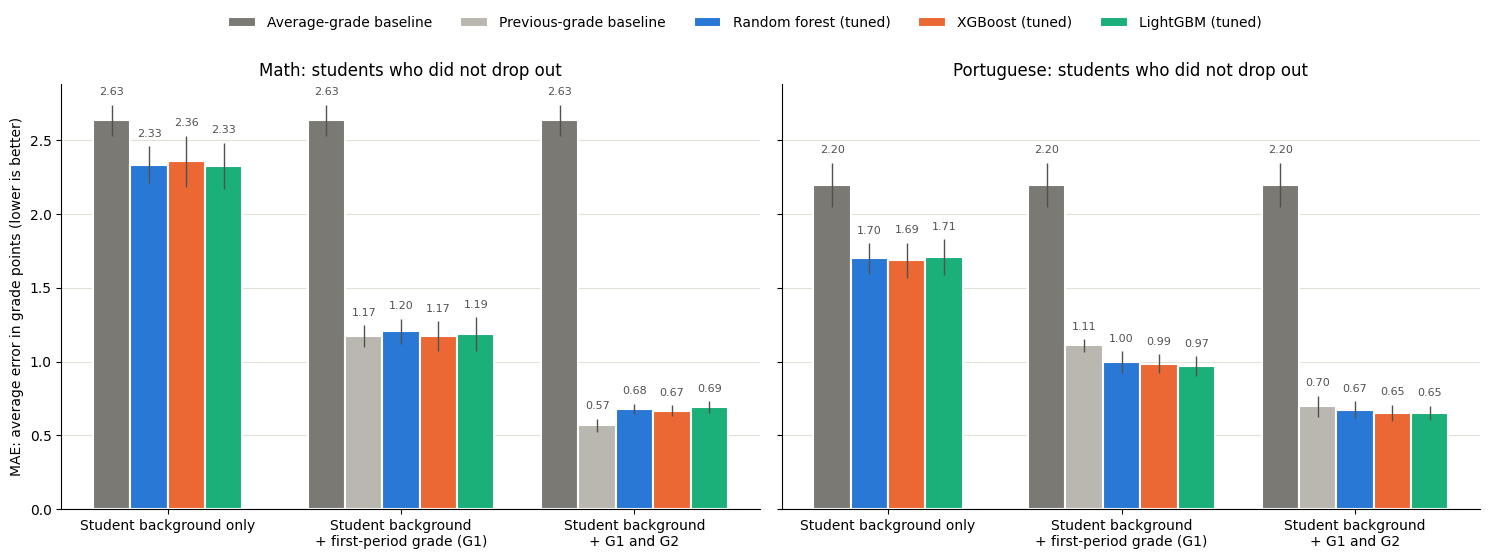

,Random forest untuned,Random forest tuned,XGBoost untuned,XGBoost tuned,LightGBM untuned,LightGBM tuned,Average-grade baseline
dataset,,,,,,,
"Math: student background + first- and second-period grades (G1, G2)",0.667,0.679,0.689,0.666,0.753,0.692,2.634
Math: student background + first-period grade (G1),1.206,1.204,1.215,1.172,1.243,1.188,2.634
Math: student background only,2.356,2.334,2.391,2.357,2.431,2.326,2.634
"Portuguese: student background + first- and second-period grades (G1, G2)",0.671,0.674,0.678,0.653,0.679,0.652,2.197
Portuguese: student background + first-period grade (G1),0.998,0.996,0.989,0.986,1.000,0.970,2.197
Portuguese: student background only,1.719,1.699,1.721,1.686,1.740,1.709,2.197


In [36]:
# colors: grays for the baselines, one fixed color per tuned model (same in every graph)
model_colors = {
    'Average-grade baseline': '#7a7974',
    'Previous-grade baseline': '#b9b7b0',
    'Random forest (tuned)': '#2a78d6',
    'XGBoost (tuned)': '#eb6834',
    'LightGBM (tuned)': '#1baf7a',
}
short_labels = {
    'student background only': 'Student background only',
    'student background + first-period grade (G1)': 'Student background\n+ first-period grade (G1)',
    'student background + first- and second-period grades (G1, G2)': 'Student background\n+ G1 and G2',
}


def plot_mae_vs_dummy(table, subjects=('Math', 'Portuguese'), width=0.16):
    """Grouped bars: MAE of the tuned models next to the dummy (and previous-grade) baselines."""
    fig, axes = plt.subplots(1, len(subjects), figsize=(15, 5.5), sharey=True)
    for ax, subject in zip(axes, subjects):
        for g, (label, short) in enumerate(short_labels.items()):
            rows = table[table['dataset'] == f'{subject}: {label}']
            # order the bars the same way in every group; skip models not in this group
            ordered = [rows[rows['model'].str.startswith(key)] for key in model_colors]
            ordered = [r.iloc[0] for r in ordered if len(r)]
            offsets = (np.arange(len(ordered)) - (len(ordered) - 1) / 2) * width
            for off, row in zip(offsets, ordered):
                key = next(k for k in model_colors if row['model'].startswith(k))
                ax.bar(g + off, row['MAE'], width, yerr=row['MAE_std'], color=model_colors[key],
                       edgecolor='white', linewidth=1.5, error_kw={'elinewidth': 1, 'ecolor': '#52514e'},
                       label=key if g == 2 else None)
                ax.text(g + off, row['MAE'] + row['MAE_std'] + 0.05, f"{row['MAE']:.2f}",
                        ha='center', va='bottom', fontsize=8, color='#52514e')
        ax.set_xticks(range(len(short_labels)))
        ax.set_xticklabels(short_labels.values())
        ax.set_title(f'{subject}: students who did not drop out')
        ax.grid(axis='y', color='#e1e0d9', linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylabel('MAE: average error in grade points (lower is better)')
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.02))
    plt.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()


plot_mae_vs_dummy(tuned_table)

# untuned (hand-picked settings, 5 x 3 folds) vs tuned (5 folds) MAE for each model
untuned = did_not_drop_out_table.pivot(index='dataset', columns='model', values='MAE')
tuned = tuned_table.pivot(index='dataset', columns='model', values='MAE')
comparison = pd.DataFrame({
    f'{m} {kind}': (untuned[m] if kind == 'untuned' else tuned[f'{m} (tuned)'])
    for m in ['Random forest', 'XGBoost', 'LightGBM'] for kind in ['untuned', 'tuned']
}).loc[tuned.index]
comparison['Average-grade baseline'] = tuned['Average-grade baseline']
comparison.round(3)

### What tuning changed
MAE (average error in grade points; lower is better):

| | Math: before → after tuning | Portuguese: before → after tuning |
|---|---|---|
| **Student background only**: dummy | 2.63 | 2.20 |
| Random forest | 2.36 → 2.33 | 1.72 → 1.70 |
| XGBoost | 2.39 → 2.36 | 1.72 → **1.69** |
| LightGBM | 2.43 → **2.33** | 1.74 → 1.71 |
| **+ first-period grade (G1)**: previous-grade baseline (G3 = G1) | 1.17 | 1.11 |
| Random forest | 1.21 → 1.20 | 1.00 → 1.00 |
| XGBoost | 1.22 → **1.17** | 0.99 → 0.99 |
| LightGBM | 1.24 → 1.19 | 1.00 → **0.97** |
| **+ G1 and G2**: previous-grade baseline (G3 = G2) | **0.57** | 0.70 |
| Random forest | 0.67 → 0.68 | 0.67 → 0.67 |
| XGBoost | 0.69 → 0.67 | 0.68 → 0.65 |
| LightGBM | 0.75 → 0.69 | 0.68 → **0.65** |

- **Tuning helped LightGBM the most.** It improved by 0.05 to 0.10 grade points in math, where its hand-picked settings were the weakest, and it is now the best (or tied for best) model in 4 of the 6 cases. XGBoost improved a little. Random forest barely changed, because its default settings were already close to its best.
- **The gains are small compared with the noise.** The improvements are at most 0.1 grade points, while each model's MAE varies by about ±0.15 to 0.2 across folds. The three tuned models are still essentially tied. (The before and after numbers also come from slightly different folds, 15 vs 5, so differences of a few hundredths are not meaningful.)
- **Against the dummy predictor:** with student background only, the tuned models cut the error by about 0.3 grade points in math (2.63 → 2.33, R² ≈ 0.21) and 0.5 in Portuguese (2.20 → 1.69, R² ≈ 0.36). That is a real improvement, but most of a student's final grade is still unexplained.
- **Against the previous-grade baseline:**
  - In math, tuned XGBoost only ties G3 = G1 (1.17), and copying G2 (0.57) still beats every tuned model (best 0.67).
  - In Portuguese, the tuned models beat copying the previous grade (0.97 vs 1.11 with G1, and 0.65 vs 0.70 with G1 and G2).
- **Takeaway:** tuning confirmed the earlier picture instead of changing it. On this little data, which grades are available matters far more than which model is used or how it is tuned.

**About the best-settings tables.** Most searches chose a low learning rate (about 0.01 to 0.015), small trees (LightGBM `num_leaves` = 8, XGBoost `max_depth` 2 to 4), and few students per leaf (`min_child_samples` = 5). The same combination often wins on several datasets because every search draws the same 25 random candidates (same `random_state`), and the same candidate ends up the best of those 25.

## Which features the models rely on (feature importance)
Tree models can report how much each feature contributed to their predictions:
- **Random forest:** for each feature, how much the splits on that feature reduced the prediction error, added up over all the trees.
- **XGBoost and LightGBM:** the same idea (total gain): how much the splits on that feature improved the model, added up over all the trees.

Each model's importances are scaled to add up to 1, so the bars show **each feature's share of the model's total importance**, and the three models can be compared side by side.

These graphs use the tuned models fit on **student background only**. With G2 included, G2 takes almost all the importance (see the second graph), which hides everything else.

**How to read them carefully:**
- **Importance shows what a model uses, not what causes a grade.** Students with past failures get lower grades, but that doesn't mean the failure itself causes the grade.
- **Correlated features share the credit.** Medu and Fedu (parents' education), or Dalc and Walc (weekday and weekend alcohol use), carry overlapping information, so the model may split the credit between them or favor one.
- **Features with many distinct values can look more important.** `absences` (0 to 75) and `age` offer many possible split points, while a 0/1 column offers only one. That can inflate their scores a little.

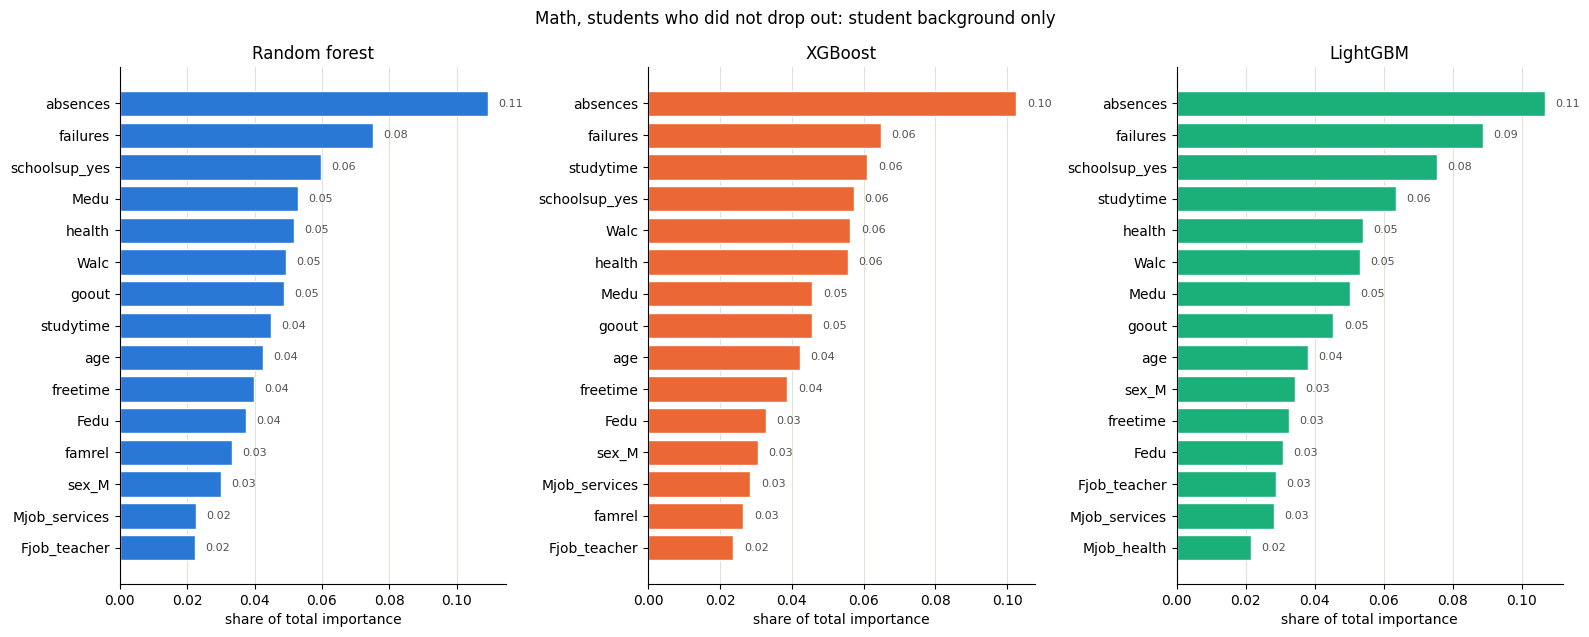

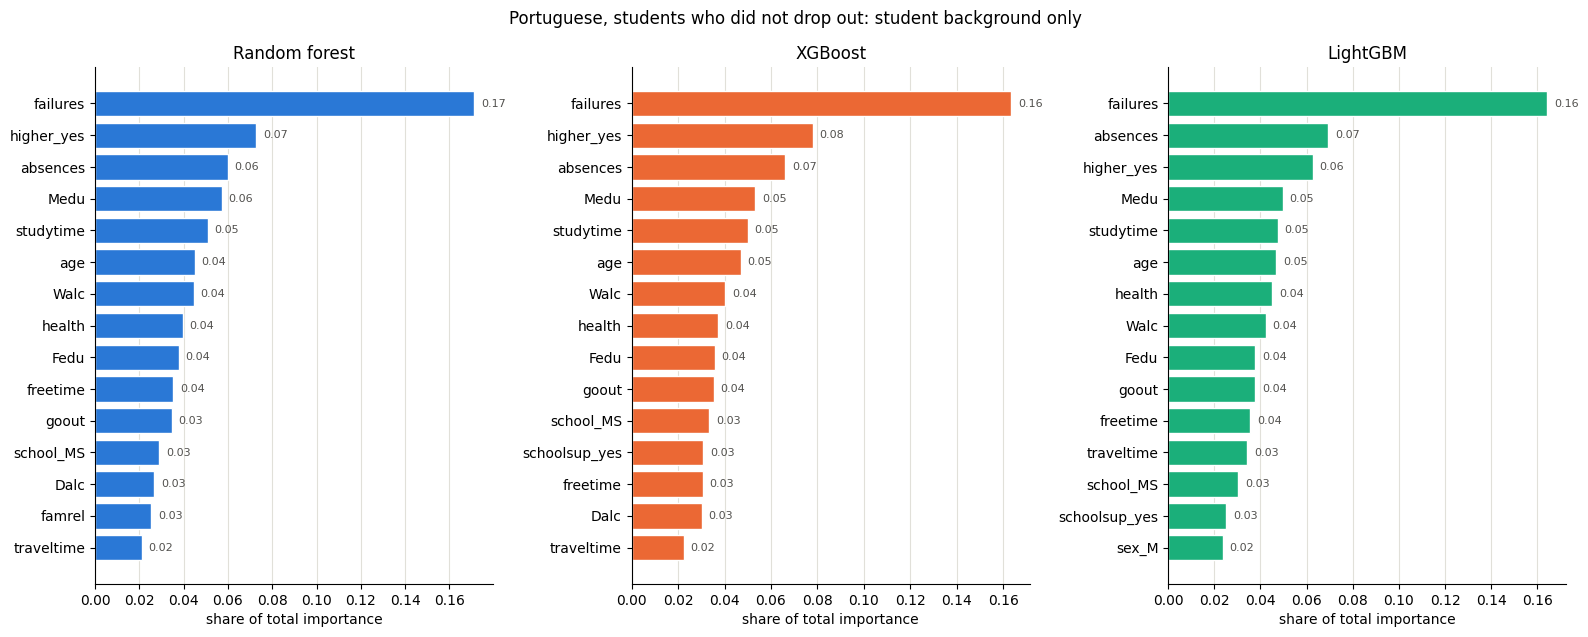

In [37]:
def plot_feature_importance(fitted_models, feature_names, title, top=15):
    """One bar chart per model: each feature's share of the model's total importance (top features only)."""
    fig, axes = plt.subplots(1, len(fitted_models), figsize=(16, 0.33 * top + 1.5))
    for ax, (model_name, model) in zip(axes, fitted_models.items()):
        importance = pd.Series(model.feature_importances_, index=feature_names)
        importance = (importance / importance.sum()).nlargest(top)[::-1]   # share of total, biggest on top
        ax.barh(importance.index, importance.values, color=model_colors[model_name], edgecolor='white')
        for i, v in enumerate(importance.values):
            ax.text(v + 0.003, i, f'{v:.2f}', va='center', fontsize=8, color='#52514e')
        ax.set_title(model_name.replace(' (tuned)', ''))
        ax.set_xlabel('share of total importance')
        ax.grid(axis='x', color='#e1e0d9', linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


for subject, df in [('Math', math_stayed), ('Portuguese', por_stayed)]:
    label = 'student background only'
    X, _ = encode(df, 'G3', drop=feature_sets[label])
    fitted = {m: tuned_fits[(subject, label, m)].best_estimator_
              for m in ['Random forest (tuned)', 'XGBoost (tuned)', 'LightGBM (tuned)']}
    plot_feature_importance(fitted, X.columns, f'{subject}, students who did not drop out: {label}')

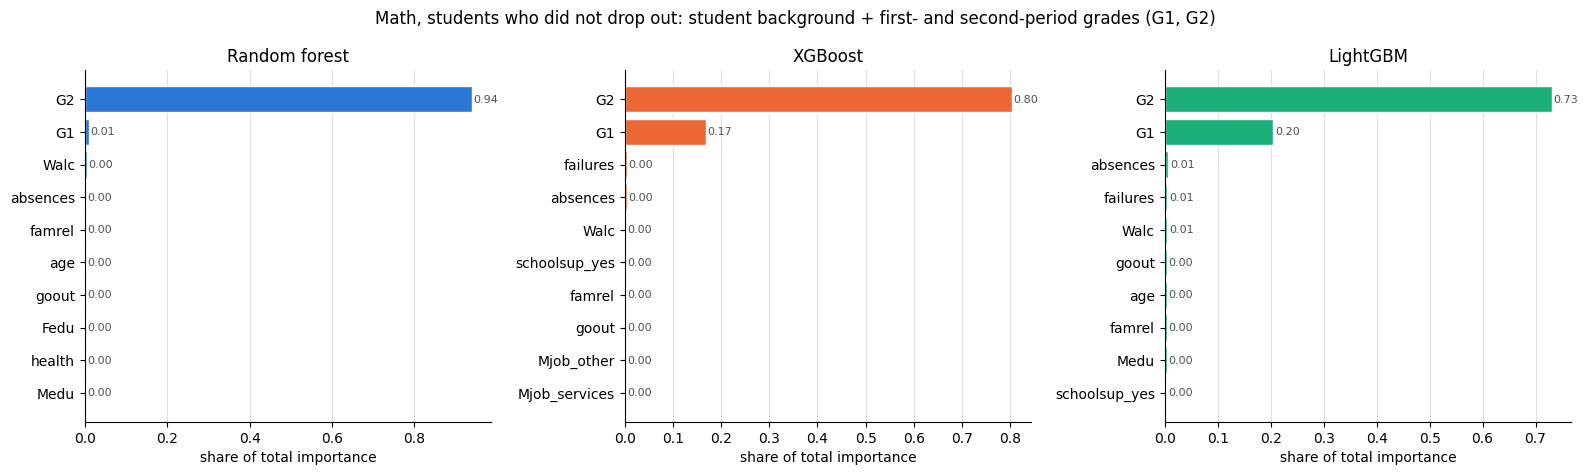

In [38]:
label = 'student background + first- and second-period grades (G1, G2)'
X, _ = encode(math_stayed, 'G3', drop=feature_sets[label])
fitted = {m: tuned_fits[('Math', label, m)].best_estimator_
          for m in ['Random forest (tuned)', 'XGBoost (tuned)', 'LightGBM (tuned)']}
plot_feature_importance(fitted, X.columns, f'Math, students who did not drop out: {label}', top=10)

### What the importance graphs show
- **`failures` (number of past class failures) is the most important feature overall**, and the clear leader in Portuguese (about 0.16 to 0.17 of total importance in all three models). This matches the correlation analysis, where `failures` had the strongest correlation with the final grade.
- **Math:** `absences`, `failures` and `schoolsup_yes` (extra school support) are at the top for all three models. Students who get extra school support tend to be the ones already struggling, so this is a sign of difficulty, not evidence that support lowers grades. Study habits (`studytime`), health, alcohol (`Walc`), and parents' education (`Medu`) come next.
- **Portuguese:** after `failures` comes `higher_yes`, meaning the student wants to go on to higher education, followed by `absences`, `Medu` and `studytime`. A student's own plans and past record matter more than family details.
- **The three models mostly agree** on the top features, even though they build their trees differently, which makes the ranking more trustworthy.
- **With G1 and G2 included**, G2 dominates. It takes 73 to 94% of the importance depending on the model, and G1 and G2 together take over 90% in all three, so the student background features add very little once the earlier grades are known. This is the same conclusion as the "G3 = G2" baseline.

## Part 3: How sure are we?

A single predicted grade is not very useful without a sense of how far off it could be. So here the predictions get a range using split conformal prediction (an idea from arXiv papers on grade data, for example Morsomme and Smirnov). The 357 math students who stayed are split 60/20/20 into train, calibration, and test. The model is trained on the training part, then on the calibration part I measure how far off each prediction is. The 80th percentile of those errors (alpha = 0.2) becomes a plus or minus range around every test prediction, and if the calibration students look like the test students, about 80% of real grades should land inside the range. A student is flagged as "may fail" when the lower end of their range is below 10.

Only three models from Part 2 are used (ridge, random forest, and LightGBM, with the hand-picked settings from before tuning), plus the previous-grade baseline, since a copied grade can get a range the same way. With only about 72 test students per split, one split is noisy, so everything is repeated over 30 random splits and averaged, at all three information levels.

How to read the columns (averaged over the 30 splits): MAE is the average error in grade points. Coverage is the share of test students whose real G3 falls inside their range (the goal is 0.80). Interval width is the full width of the range in grade points. Failing flagged is the share of failing students (G3 below 10) whose lower end is below 10, so higher is better. Passing flagged is the same for passing students, which are the false alarms, so lower is better.

In [19]:
from sklearn.model_selection import train_test_split

alpha = 0.2
pass_mark = 10

def conformal_half_width(calibration_grades, calibration_predictions):
    """Split conformal: the 80th percentile of the errors on the calibration students."""
    scores = np.abs(calibration_grades - calibration_predictions)
    n = len(scores)
    level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return np.quantile(scores, level, method='higher')


def interval_models(X):
    """Ridge, random forest and LightGBM (same settings as before) plus the previous-grade baseline."""
    models = default_models('regression')
    chosen = {name: models[name] for name in ['Ridge regression', 'Random forest', 'LightGBM']}
    if 'G2' in X:
        chosen['Previous-grade baseline (G3 = G2)'] = PreviousGradeBaseline('G2')
    elif 'G1' in X:
        chosen['Previous-grade baseline (G3 = G1)'] = PreviousGradeBaseline('G1')
    return chosen

In [20]:
interval_rows = []
for label, drop in feature_sets.items():
    X, y = encode(math_stayed, 'G3', drop=drop)
    for seed in range(30):
        # 60% train, 20% calibration, 20% test
        rest_index, test_index = train_test_split(X.index, test_size=0.2, random_state=seed)
        train_index, calibration_index = train_test_split(rest_index, test_size=0.25, random_state=seed)
        for model_name, model in interval_models(X).items():
            model.fit(X.loc[train_index], y.loc[train_index])
            half_width = conformal_half_width(y.loc[calibration_index], model.predict(X.loc[calibration_index]))
            predictions = model.predict(X.loc[test_index])
            lower, upper = predictions - half_width, predictions + half_width
            grades = y.loc[test_index]
            failing = (grades < pass_mark).values
            interval_rows.append({
                'information': label, 'model': model_name,
                'MAE': np.mean(np.abs(grades - predictions)),
                'coverage': np.mean((grades >= lower) & (grades <= upper)),
                'interval width': 2 * half_width,
                'failing flagged': np.mean(lower[failing] < pass_mark),
                'passing flagged': np.mean(lower[~failing] < pass_mark),
            })

interval_results = pd.DataFrame(interval_rows)
interval_table = interval_results.groupby(['information', 'model'], sort=False).mean()
interval_table.round(3)

MAE  \
information                                        model                                      
student background only                            Ridge regression                   2.486   
                                                   Random forest                      2.373   
                                                   LightGBM                           2.437   
student background + first-period grade (G1)       Ridge regression                   1.238   
                                                   Random forest                      1.222   
                                                   LightGBM                           1.253   
                                                   Previous-grade baseline (G3 = G1)  1.183   
student background + first- and second-period g... Ridge regression                   0.704   
                                                   Random forest                      0.702   
                                                   LightGBM                           0.800   
                                                   Previous-grade baseline (G3 = G2)  0.563   

                                                                                      coverage  \
information                                        model                                         
student background only                            Ridge regression                      0.825   
                                                   Random forest                         0.839   
                                                   LightGBM                              0.838   
student background + first-period grade (G1)       Ridge regression                      0.841   
                                                   Random forest                         0.827   
                                                   LightGBM                              0.827   
                                                   Previous-grade baseline (G3 = G1)     0.900   
student background + first- and second-period g... Ridge regression                      0.838   
                                                   Random forest                         0.817   
                                                   LightGBM                              0.819   
                                                   Previous-grade baseline (G3 = G2)     0.937   

                                                                                      interval width  \
information                                        model                                               
student background only                            Ridge regression                            8.744   
                                                   Random forest                               8.316   
                                                   LightGBM                                    8.347   
student background + first-period grade (G1)       Ridge regression                            4.298   
                                                   Random forest                               4.130   
                                                   LightGBM                                    4.255   
                                                   Previous-grade baseline (G3 = G1)           4.000   
student background + first- and second-period g... Ridge regression                            2.506   
                                                   Random forest                               2.419   
                                                   LightGBM                                    2.752   
                                                   Previous-grade baseline (G3 = G2)           2.000   

                                                                                      failing flagged  \
information                                        model                                                
student backgr

The ranges do what they promise on average: coverage is 0.817 to 0.841 for the three models (the goal is 0.80). The ranges also shrink a lot as more is known. For the random forest the range is 8.316 grade points wide with background only, 4.130 after G1, and 2.419 after G2 (ridge: 8.744, 4.298, 2.506, and LightGBM: 8.347, 4.255, 2.752). With background only a range about 8 points wide on a 0 to 20 scale is not saying much, and the "may fail" flag is raised for 0.891 to 0.959 of the passing students. After G1 the false alarms drop to 0.436 to 0.463, and after G2 to 0.313 to 0.369, while failing students are still almost all flagged (1.000 for all three models at both levels, and 0.977 to 0.999 with background only).

The previous-grade baseline does better than the models at both levels where it exists. After G2 it has the narrowest range (2.000 vs 2.419 to 2.752), the fewest false alarms (0.233 vs 0.313 to 0.369), and the lowest MAE (0.563 vs 0.702 to 0.800), and it still flags 0.993 of the failing students. After G1 it is ahead by less (range 4.000, false alarms 0.393, MAE 1.183, against 4.130 to 4.298, 0.436 to 0.463, and 1.222 to 1.253 for the models). Its coverage is above 0.80 (0.900 and 0.937), which is allowed (the method only promises at least 0.80): grades are whole numbers, and about half of the math students have G3 exactly equal to G2 (Part 2), so the 80th percentile of its errors lands on a whole number of points (a width of exactly 2.000 and 4.000 in every split) and that range covers more than 80%. So in math the models only give a range that copying cannot give at the background only level, where there is no grade to copy, and there the range is very wide. That matches the Part 2 results.

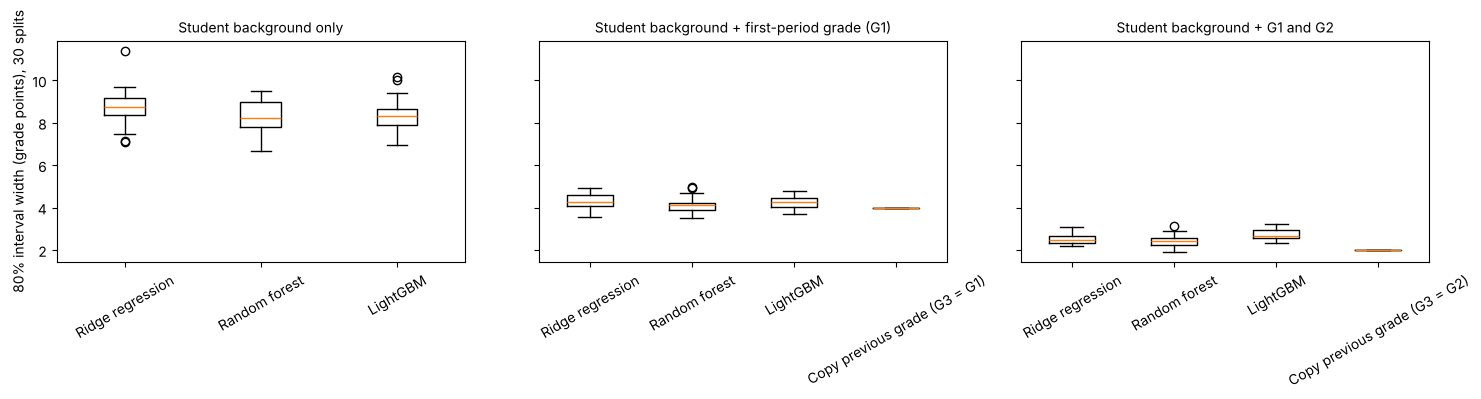

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (label, short) in zip(axes, short_labels.items()):
    rows = interval_results[interval_results['information'] == label]
    names = list(dict.fromkeys(rows['model']))
    ax.boxplot([rows.loc[rows['model'] == n, 'interval width'] for n in names],
               tick_labels=[n.replace('Previous-grade baseline', 'Copy previous grade') for n in names])
    ax.set_title(short.replace('\n', ' '), fontsize=10)
    ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('80% interval width (grade points), 30 splits')
plt.tight_layout()
plt.show()

The same picture over the 30 splits: the width of the range drops from left to right as more grades are known, and ridge, random forest, and LightGBM mostly overlap within a level. The previous-grade baseline is a flat line (a width of exactly 4 after G1 and exactly 2 after G2 in every split), so it is also the most stable.

### Why the dropouts are kept out of this

To check that setting the dropouts aside matters for the ranges too, here is one random forest trained and calibrated on every math student, dropouts included, at the G1 and G2 level (same 60/20/20 split and 30 repeats, stratified on dropout). `absences` is left out here as in Part 1, since it gives the dropouts away by accident.

In [22]:
# one random forest for every math student (dropouts included), G1 and G2 level, same split and interval code
X_all, y_all = encode(math_all, 'G3', drop=('dropped_out', 'absences'))
all_rows = []
for seed in range(30):
    rest_index, test_index = train_test_split(X_all.index, test_size=0.2, stratify=math_all['dropped_out'], random_state=seed)
    train_index, calibration_index = train_test_split(rest_index, test_size=0.25,
                                                      stratify=math_all.loc[rest_index, 'dropped_out'], random_state=seed)
    model = default_models('regression')['Random forest'].fit(X_all.loc[train_index], y_all.loc[train_index])
    half_width = conformal_half_width(y_all.loc[calibration_index], model.predict(X_all.loc[calibration_index]))
    predictions = model.predict(X_all.loc[test_index])
    grades = y_all.loc[test_index]
    covered = ((grades >= predictions - half_width) & (grades <= predictions + half_width)).values
    dropped = (grades == 0).values
    all_rows.append({'coverage, everyone': covered.mean(),
                     'coverage, dropouts': covered[dropped].mean(),
                     'coverage, students who stayed': covered[~dropped].mean(),
                     'interval width': 2 * half_width,
                     'MAE, dropouts': np.mean(np.abs(grades[dropped] - predictions[dropped])),
                     'MAE, students who stayed': np.mean(np.abs(grades[~dropped] - predictions[~dropped]))})
pd.DataFrame(all_rows).mean().round(3)

coverage, everyone               0.816
coverage, dropouts               0.233
coverage, students who stayed    0.882
interval width                   3.792
MAE, dropouts                    4.499
MAE, students who stayed         0.913
dtype: float64

Over everyone the coverage looks fine (0.816), but that hides two groups. The students who stayed are covered 0.882 of the time and the dropouts only 0.233 of the time, with an MAE of 4.499 on the dropouts against 0.913 on the students who stayed. The range is also 3.792 points wide, compared with 2.419 for the random forest trained on the students who stayed only (table above). So the dropouts make the range wider for everyone and the range still misses most of the dropouts. (This forest also leaves out absences, so the two widths are not a perfect like for like.) That is the reason for treating "who drops out" (Part 1) and "what grade will everyone else get" (Part 2) as two separate questions.

## Part 4: What if there is little data? Borrowing from the Portuguese course

The math course has far fewer students than the Portuguese course, and many of the same students are in both. Schwerter et al. used what was learned from earlier groups of students as the starting guess for a new group, so here a model trained on the Portuguese course is the starting guess for math. A ridge is trained on Portuguese students and makes a first guess for each math student, then a second ridge trained on the math students learns what is left over. That is compared with a ridge trained on the math students alone, using only 20 up to 250 math students. This is at the student background + G1 level (with G2 there is little left for a starting guess to add), on the students who did not drop out, and each size is repeated 30 times. The test set is 20% of the math students who stayed, and I also measure two reference points that use no math students at all: the Portuguese ridge by itself, and predicting the average math grade.

In [23]:
import warnings
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import RidgeCV

warnings.filterwarnings('ignore', category=UserWarning)   # small training sets often miss a rare category, which is fine

# Portuguese students who also look like a math student (same 13 columns the dataset's own merge script uses)
match_columns = ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
                 'Mjob', 'Fjob', 'reason', 'nursery', 'internet']
math_keys = set(map(tuple, math_class[match_columns].values))
looks_like_math_student = np.array([tuple(row) in math_keys for row in por_stayed[match_columns].values])

port_clean = por_stayed[~looks_like_math_student].reset_index(drop=True)
print('Portuguese students who did not drop out:', len(por_stayed))
print('of those, students who also look like a math student:', looks_like_math_student.sum())
print('Portuguese students kept for the prior:', len(port_clean))

Portuguese students who did not drop out: 634
of those, students who also look like a math student: 369
Portuguese students kept for the prior: 265


369 of the 634 Portuguese students who did not drop out match a math student on the 13 columns, which leaves 265 for the starting guess. The match is approximate (it is the same rule the dataset's own merge script uses, and two different students can share the same 13 values), but it keeps the Portuguese model from having already seen students it is later tested on.

In [24]:
def make_features(data):
    """Student background + G1 (no G2, no G3)."""
    return data.drop(columns=['G2', 'G3'])

def make_ridge(features):
    text_columns = features.select_dtypes(exclude='number').columns
    preprocessor = ColumnTransformer([('text', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), text_columns)],
                                     remainder=StandardScaler())
    return make_pipeline(preprocessor, RidgeCV(alphas=np.logspace(-1, 3, 9)))

class RidgeFromScratch:
    def fit(self, features, grades):
        self.model = make_ridge(features).fit(features, grades)
        return self
    def predict(self, features):
        return self.model.predict(features)

class RidgeWithPortuguesePrior:
    """The Portuguese ridge makes a first guess, then a second ridge learns what is left over on the math students."""
    def __init__(self, port_features, port_grades):
        self.prior = make_ridge(port_features).fit(port_features, port_grades)
    def fit(self, features, grades):
        self.residual_model = make_ridge(features).fit(features, grades - self.prior.predict(features))
        return self
    def predict(self, features):
        return self.prior.predict(features) + self.residual_model.predict(features)

math_features = make_features(math_stayed)
port_features = make_features(port_clean)

In [25]:
sizes = [20, 40, 80, 160, 250]
curve_rows = []
for seed in range(30):
    pool_index, test_index = train_test_split(math_stayed.index, test_size=0.2, random_state=seed)
    test_grades = math_stayed.loc[test_index, 'G3']
    rng = np.random.RandomState(seed)
    for size in sizes:
        train_index = rng.choice(pool_index, size=size, replace=False)
        for name, model in [('Ridge from scratch', RidgeFromScratch()),
                            ('Ridge + Portuguese prior', RidgeWithPortuguesePrior(port_features, port_clean['G3']))]:
            predictions = model.fit(math_features.loc[train_index], math_stayed.loc[train_index, 'G3']).predict(math_features.loc[test_index])
            curve_rows.append({'seed': seed, 'size': size, 'model': name,
                               'MAE': np.mean(np.abs(test_grades - predictions)),
                               'RMSE': np.sqrt(np.mean((test_grades - predictions) ** 2))})
    prior_only = make_ridge(port_features).fit(port_features, port_clean['G3']).predict(math_features.loc[test_index])
    for name, predictions in [('Portuguese prior only', prior_only),
                              ('Predict the math mean', math_stayed.loc[pool_index, 'G3'].mean())]:
        curve_rows.append({'seed': seed, 'size': 0, 'model': name,
                           'MAE': np.mean(np.abs(test_grades - predictions)),
                           'RMSE': np.sqrt(np.mean((test_grades - predictions) ** 2))})

curve = pd.DataFrame(curve_rows)
curve_table = curve[curve['size'] > 0].pivot_table(index='size', columns='model', values='MAE')
curve_table['gain'] = curve_table['Ridge from scratch'] - curve_table['Ridge + Portuguese prior']
print('MAE')
print(curve_table.round(3))
print()
print('reference points with no math students (MAE and RMSE):')
print(curve[curve['size'] == 0].groupby('model')[['MAE', 'RMSE']].mean().round(3))

MAE
model  Ridge + Portuguese prior  Ridge from scratch   gain
size                                                      
20                        1.347               1.878  0.531
40                        1.326               1.573  0.247
80                        1.253               1.338  0.086
160                       1.221               1.251  0.030
250                       1.196               1.216  0.019

reference points with no math students (MAE and RMSE):
                         MAE   RMSE
model                              
Portuguese prior only  1.384  1.680
Predict the math mean  2.617  3.192


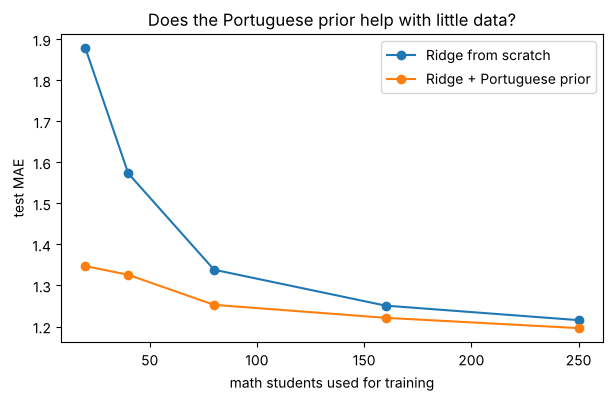

In [26]:
plt.figure(figsize=(7, 4))
for name in ['Ridge from scratch', 'Ridge + Portuguese prior']:
    mean_curve = curve[curve['model'] == name].groupby('size')['MAE'].mean()
    plt.plot(mean_curve.index, mean_curve.values, marker='o', label=name)
plt.xlabel('math students used for training')
plt.ylabel('test MAE')
plt.title('Does the Portuguese prior help with little data?')
plt.legend()
plt.show()

The Portuguese starting guess helps most when there is little math data, and the help fades as the math training set grows: with 20 math students the MAE is 1.347 with it vs 1.878 from scratch (a gain of 0.531), then a gain of 0.247 at 40 students, 0.086 at 80, 0.030 at 160, and 0.019 at 250 (1.196 vs 1.216). With no math students at all, the Portuguese model by itself gets an MAE of 1.384, which is much better than predicting the math average (2.617) and better than a ridge trained from scratch on 20 or 40 math students (1.878 and 1.573). Training from scratch only overtakes it at around 80 students (1.338). The RMSE of those two reference points is 1.680 and 3.192. This is a ridge on one pair of courses at the G1 level, and the 265 Portuguese students come from an approximate match, so I would treat the exact gains as rough.

## Putting it together

- **Who is likely to drop out?** Not much can be said before the year starts: with background only the best PR-AUC is 0.29 in math (guessing scores 0.096). With G1 it is 0.41, and with G1 and G2 it is 0.68 (LightGBM), partly because 13 of the 38 math dropouts already have G2 = 0.
- **What grade will everyone else get?** Background only explains about 17% of the variance in math final grades (best MAE 2.36 against 2.64 for guessing the average). With G1 the models are about level with copying G1 (1.21 vs 1.17), and with G1 and G2 copying G2 is better in math (0.57 vs 0.67 for the best model), while in Portuguese the models are slightly better than copying.
- **How sure are we?** The 80% ranges are about 8 points wide with background only, 4 after G1, and 2.4 after G2 (random forest), and copying the previous grade gets an equal or better range. The Portuguese starting guess helps when there are few math students (MAE 1.347 vs 1.878 at 20 students) and the gain is almost gone by 250.

## Appendix: extra checks from the first pass

These are not needed for the three questions. The first part is the collinearity report with G1 as the target (to see how hard G1 is to predict from background alone), and the second part is a closer look at one decision tree from the tuned random forest.

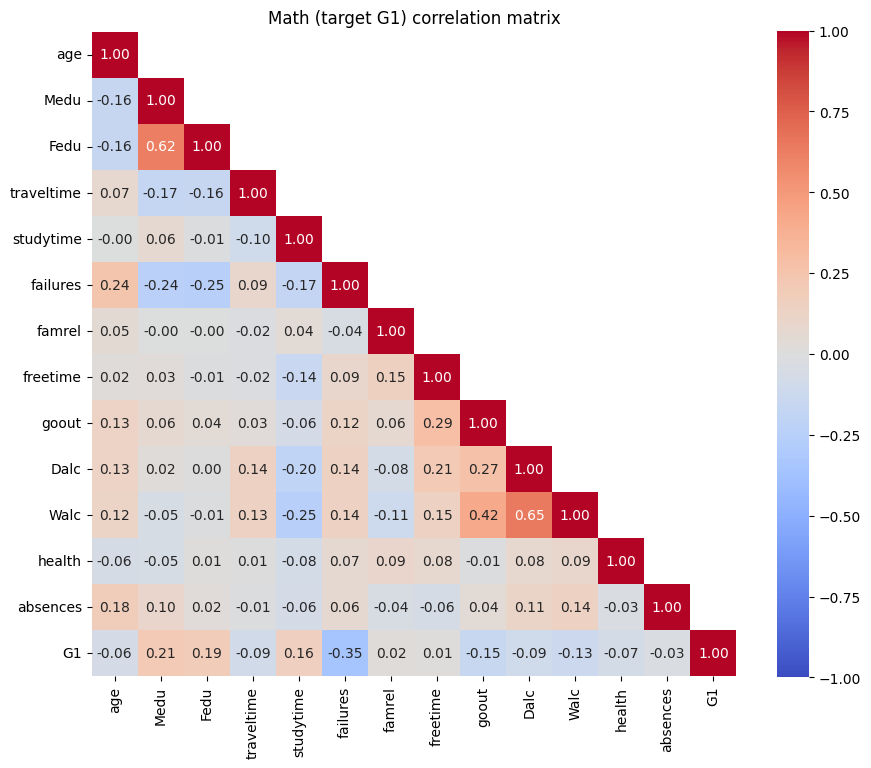

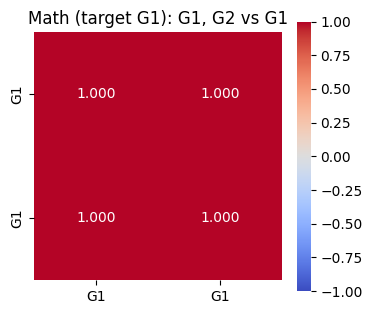

===== Math (target G1) =====
correlation with G1:
failures     -0.355
Medu          0.205
Fedu          0.190
studytime     0.161
goout        -0.149
Walc         -0.126
Dalc         -0.094
traveltime   -0.093

predictor pairs with |r| >= 0.8:
  none

condition number of correlation matrix (lambda_max / lambda_min): 8.04
condition number of standardized X: 2.84

VIF:
Walc          2.09
Dalc          1.81
Medu          1.75
Fedu          1.71
goout         1.35
failures      1.20
freetime      1.18
age           1.16
studytime     1.13
absences      1.08
famrel        1.08
traveltime    1.07
health        1.05


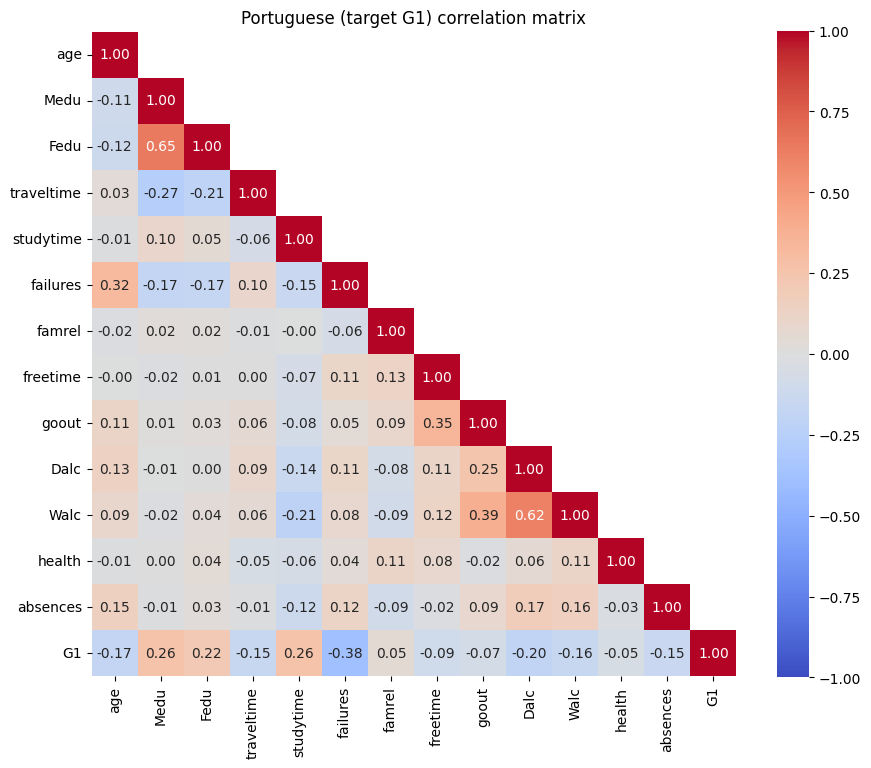

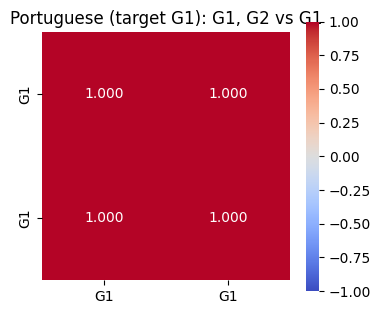

===== Portuguese (target G1) =====
correlation with G1:
failures     -0.384
studytime     0.261
Medu          0.260
Fedu          0.218
Dalc         -0.195
age          -0.174
Walc         -0.156
traveltime   -0.154

predictor pairs with |r| >= 0.8:
  none

condition number of correlation matrix (lambda_max / lambda_min): 7.11
condition number of standardized X: 2.67

VIF:
Walc          1.90
Medu          1.81
Fedu          1.76
Dalc          1.66
goout         1.37
failures      1.20
freetime      1.19
age           1.17
traveltime    1.10
studytime     1.09
absences      1.08
famrel        1.07
health        1.05


In [11]:
math_g1_report = collinearity_report(math_class.drop(columns=['G2', 'G3']), target='G1', name='Math (target G1)')
por_g1_report = collinearity_report(portugese_class.drop(columns=['G2', 'G3']), target='G1', name='Portuguese (target G1)')

### What the results show (target G1)
- **Without the other grades, nothing is strongly related to G1.** The strongest feature is `failures` (past class failures): r = −0.355 in math and −0.384 in Portuguese. Next come parents' education (Medu, Fedu: about 0.19 to 0.26) and `studytime` (0.16 in math, 0.26 in Portuguese). Going out and alcohol use (goout, Walc, Dalc) have small negative correlations.
- **No collinearity problem.** No predictor pair reaches |r| = 0.8, and every VIF is at most about 2.1. The highest is Walc, from its overlap with Dalc, followed by Medu and Fedu, which overlap with each other. The condition number is 8.0 (math) and 7.1 (Portuguese) on the correlation matrix, and about 2.7 to 2.8 on the standardized X, which is well below the warning levels. Removing G2 and G3 took away the only collinear pair (G1 and G2), which is why the condition number dropped from about 21 to about 8.
- **Takeaway**: the features are clean enough for a linear model, but each one explains only a little of G1, so G1 will be much harder to predict than G3 was with G1 and G2 included. The same pattern shows up in both classes, and it is slightly stronger in Portuguese.

## One decision tree from the tuned random forest
A random forest is made of hundreds of decision trees. Each tree is trained on a random sample of students (drawn with replacement) and considers a random subset of features at each split. The forest's prediction is the **average of all its trees**. Below is the first tree of the tuned math forest (student background only), so you can see what one tree does.

**How to read a box (node):**
- **First line: the split rule**, e.g. `failures <= 0.5`. Students who meet the rule go **left (True)**, and the rest go **right (False)**.
- **`squared_error`**: how spread out the G3 grades of the students in this box are (their variance). Splits are chosen to make this smaller.
- **`samples`**: how many distinct students in this tree's random sample reach this box. The top box has about 225 of the 357 students, because each tree's sample repeats some students and leaves out others.
- **`value`**: the average G3 of those students. That is the tree's prediction for anyone who ends up in this box.
- **Color**: darker orange means a higher predicted grade.

The full tree is too big to draw (it is printed above the drawing), so only the top 3 levels are shown, and `(...)` marks where the tree continues. Below the drawing, the same tree is printed as text, down to 4 levels.

The tuned forest has 391 trees. This one has 8 levels and 59 leaves; the drawing shows the top 3 levels.


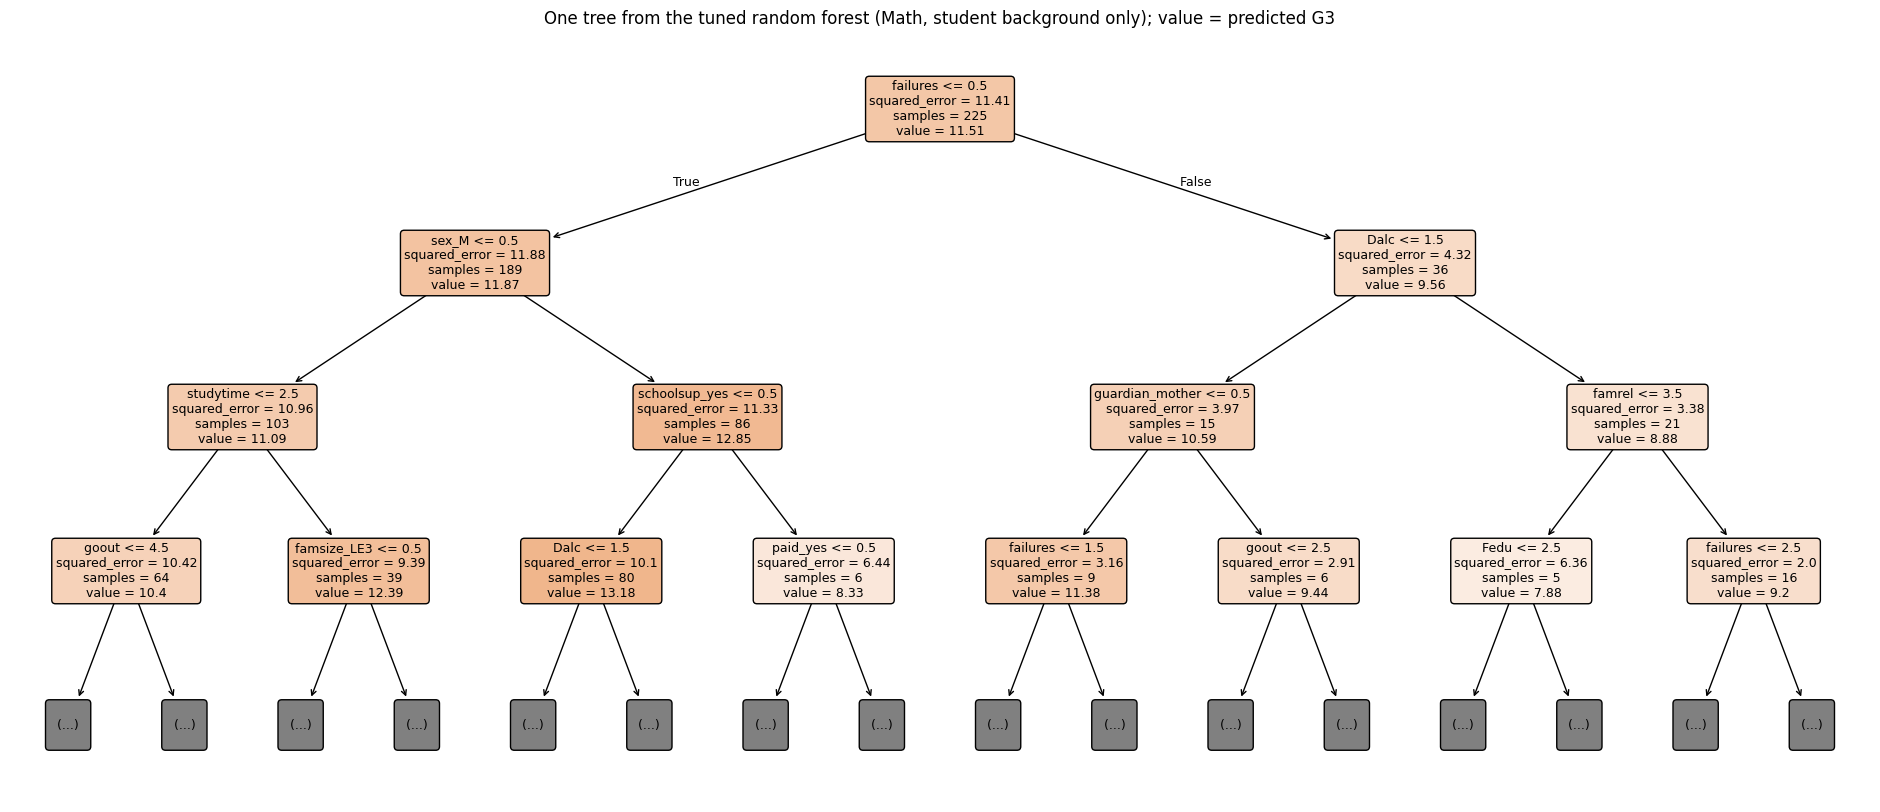

|--- failures <= 0.50
|   |--- sex_M <= 0.50
|   |   |--- studytime <= 2.50
|   |   |   |--- goout <= 4.50
|   |   |   |   |--- internet_yes <= 0.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- internet_yes >  0.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- goout >  4.50
|   |   |   |   |--- famsize_LE3 <= 0.50
|   |   |   |   |   |--- value: [6.40]
|   |   |   |   |--- famsize_LE3 >  0.50
|   |   |   |   |   |--- value: [8.50]
|   |   |--- studytime >  2.50
|   |   |   |--- famsize_LE3 <= 0.50
|   |   |   |   |--- Mjob_health <= 0.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- Mjob_health >  0.50
|   |   |   |   |   |--- value: [15.50]
|   |   |   |--- famsize_LE3 >  0.50
|   |   |   |   |--- Medu <= 2.50
|   |   |   |   |   |--- value: [11.33]
|   |   |   |   |--- Medu >  2.50
|   |   |   |   |   |--- truncated branch of depth 3
|   |--- sex_M >  0.50
|   |   |--- schoolsup_yes <= 0.50
|   |   |   |

In [39]:
from sklearn.tree import plot_tree, export_text

label = 'student background only'
X, _ = encode(math_stayed, 'G3', drop=feature_sets[label])
forest = tuned_fits[('Math', label, 'Random forest (tuned)')].best_estimator_
one_tree = forest.estimators_[0]   # the first of the forest's trees
print(f'The tuned forest has {len(forest.estimators_)} trees. This one has {one_tree.get_depth()} levels '
      f'and {one_tree.get_n_leaves()} leaves; the drawing shows the top 3 levels.')

plt.figure(figsize=(24, 10))
plot_tree(one_tree, max_depth=3, feature_names=list(X.columns), filled=True, rounded=True,
          precision=2, fontsize=9)
plt.title(f'One tree from the tuned random forest (Math, {label}); value = predicted G3')
plt.show()

# the same tree as text, one level deeper
print(export_text(one_tree, feature_names=list(X.columns), max_depth=4, decimals=2))

### What this tree shows
- **The first split is on `failures`.** Students with no past failures (left) average about 11.9, while students with one or more failures (right) average about 9.6. The tree finds that to be the single most useful question to ask first, which matches the importance graphs.
- **Further down, the tree refines the prediction** with sex, study time, extra school support, alcohol use and family relationships. For example, among students with no failures, boys without extra school support average about 13.2.
- **One tree is only an illustration.** Each tree sees different students and features, so another tree in the forest could split on different features. A single tree like this also overfits: its deepest boxes contain only a handful of students. Averaging hundreds of trees cancels out much of that noise, which is why the forest predicts better than any one tree. The feature-importance graph summarizes what all the trees together rely on.

### The full tree (what's inside the gray boxes)
The drawing above stops after 3 levels, and the gray `(...)` boxes hide the rest. The cell below draws the **whole tree**: 8 levels and 59 end boxes. The **bottom boxes on each branch are the final predictions**, and their `value` is the G3 the tree predicts for students who end up there.

The full drawing is very wide, so it is also saved as **`random_forest_tree_math.svg`** in the project1 folder. Open it in a web browser and zoom in to read any part clearly. The text version printed under the drawing is the same tree and is the easiest way to follow one path.

**Example path, followed from the top to a final prediction:**
1. no past failures (`failures <= 0.5`)
2. female (`sex_M <= 0.5`)
3. studies 5 hours a week or less (`studytime <= 2.5`)
4. doesn't go out with friends the maximum amount (`goout <= 4.5`, i.e. 1 to 4 on the 1 to 5 scale)
5. has internet at home (`internet_yes > 0.5`)
6. no family educational support (`famsup_yes <= 0.5`)
7. father is not a teacher (`Fjob_teacher <= 0.5`)
8. no extra school support (`schoolsup_yes <= 0.5`)

→ **predicted G3 = 11.9**

Remember that this is one tree out of 391. The forest's real prediction for a student is the average of all 391 trees' end-box values.

Full tree: 8 levels, 59 end boxes (final predictions)


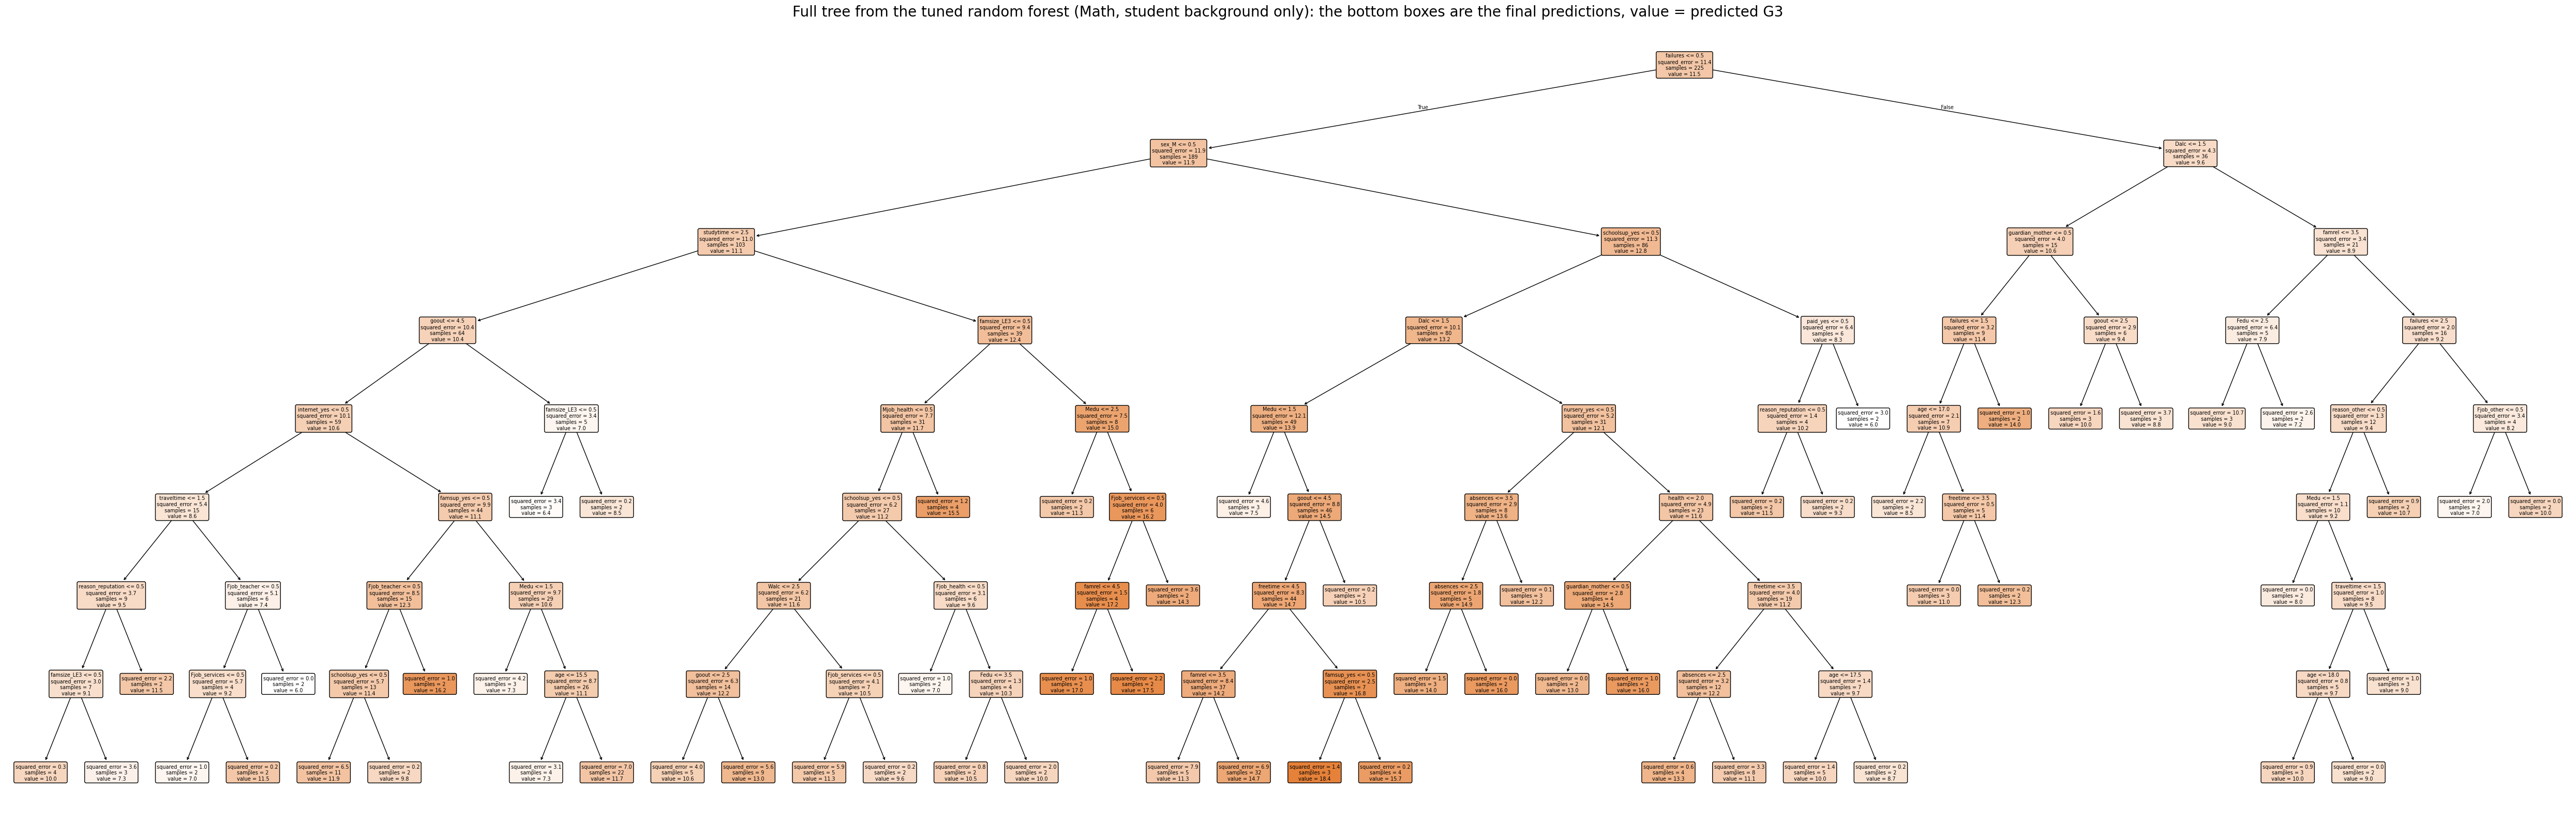

|--- failures <= 0.5
|   |--- sex_M <= 0.5
|   |   |--- studytime <= 2.5
|   |   |   |--- goout <= 4.5
|   |   |   |   |--- internet_yes <= 0.5
|   |   |   |   |   |--- traveltime <= 1.5
|   |   |   |   |   |   |--- reason_reputation <= 0.5
|   |   |   |   |   |   |   |--- famsize_LE3 <= 0.5
|   |   |   |   |   |   |   |   |--- value: [10.0]
|   |   |   |   |   |   |   |--- famsize_LE3 >  0.5
|   |   |   |   |   |   |   |   |--- value: [7.3]
|   |   |   |   |   |   |--- reason_reputation >  0.5
|   |   |   |   |   |   |   |--- value: [11.5]
|   |   |   |   |   |--- traveltime >  1.5
|   |   |   |   |   |   |--- Fjob_teacher <= 0.5
|   |   |   |   |   |   |   |--- Fjob_services <= 0.5
|   |   |   |   |   |   |   |   |--- value: [7.0]
|   |   |   |   |   |   |   |--- Fjob_services >  0.5
|   |   |   |   |   |   |   |   |--- value: [11.5]
|   |   |   |   |   |   |--- Fjob_teacher >  0.5
|   |   |   |   |   |   |   |--- value: [6.0]
|   |   |   |   |--- internet_yes >  0.5
|   |   |   |   

In [40]:
# the full tree from the cell above: every box down to the end boxes, nothing hidden in "(...)"
print(f'Full tree: {one_tree.get_depth()} levels, {one_tree.get_n_leaves()} end boxes (final predictions)')

fig = plt.figure(figsize=(64, 20))
plot_tree(one_tree, feature_names=list(X.columns), filled=True, rounded=True, precision=1, fontsize=7)
plt.title('Full tree from the tuned random forest (Math, student background only): '
          'the bottom boxes are the final predictions, value = predicted G3', fontsize=20)
fig.savefig('random_forest_tree_math.svg', bbox_inches='tight')   # vector image: open in a browser and zoom in
plt.show()

# the same full tree as text: follow a path from the top down to "value" = predicted G3
print(export_text(one_tree, feature_names=list(X.columns), decimals=1))